In [ ]:
!nvidia-smi


Sat Oct 31 20:03:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
for p in ["raw_all/svarah", "raw_data", "preprocessed_data", "output/English", "output/Telugu"]:
    os.makedirs(f"/content/drive/MyDrive/fs2/{p}", exist_ok=True)

Mounted at /content/drive


In [ ]:
!git clone https://github.com/Narmadas-31/fastspeech2-english-telugu.git /content/project
%cd /content/project/English
!ls

Cloning into '/content/project'...
fatal: could not read Username for 'https://github.com': No such device or address
[Errno 2] No such file or directory: '/content/project/English'
/content
drive  sample_data


In [ ]:
!pip install -q "datasets<4" soundfile librosa huggingface_hub pyyaml tgt g2p_en inflect unidecode pyworld tensorboard matplotlib pandas scipy

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


In [ ]:
import datasets, librosa, soundfile, pyworld, g2p_en, tgt, yaml, inflect, unidecode
print("datasets", datasets.__version__)
print("librosa", librosa.__version__)
print("all imports OK")

/usr/local/lib/python3.13/dist-packages/pyworld/__init__.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


datasets 3.6.0
librosa 0.11.0
all imports OK


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package cmudict to /root/nltk_data...
[nltk_data]   Unzipping corpora/cmudict.zip.


In [ ]:
import os
print(os.path.exists("/content/drive/MyDrive"))


True


In [ ]:
!cp /content/drive/MyDrive/fs2/generator_universal.pth.tar.zip /content/project/English/hifigan/
!cd /content/project/English/hifigan && unzip -o generator_universal.pth.tar.zip
!ls -lh /content/project/English/hifigan

cp: cannot create regular file '/content/project/English/hifigan/': No such file or directory
/bin/bash: line 1: cd: /content/project/English/hifigan: No such file or directory
ls: cannot access '/content/project/English/hifigan': No such file or directory


In [ ]:
!ls /content
!ls /content/project 2>/dev/null || echo "project NOT cloned"

drive  sample_data
project NOT cloned


In [ ]:
!git clone https://github.com/Narmadas-31/fastspeech2-english-telugu.git /content/project
%cd /content/project/English
!ls

Cloning into '/content/project'...
remote: Enumerating objects: 82, done.
remote: Counting objects: 100% (82/82), done.
remote: Compressing objects: 100% (67/67), done.
remote: Total 82 (delta 13), reused 78 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (82/82), 1.39 MiB | 12.58 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/project/English
audio	     dataset.py    lexicon	  requirements_ref.txt	transformer
checkpoints  evaluate.py   model	  synthesize.py		utils
config_ref   hifigan	   preprocessor   text
config.yaml  inference.py  preprocess.py  train.py


In [ ]:
!ls /content/project/English/hifigan

config.json  __init__.py  LICENSE  models.py


In [ ]:
import os
print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))
print("zip on Drive:", os.path.exists("/content/drive/MyDrive/fs2/generator_universal.pth.tar.zip"))

Drive mounted: True
zip on Drive: True


In [ ]:
!cp /content/drive/MyDrive/fs2/generator_universal.pth.tar.zip /content/project/English/hifigan/
!cd /content/project/English/hifigan && unzip -o generator_universal.pth.tar.zip
!ls -lh /content/project/English/hifigan

Archive:  generator_universal.pth.tar.zip
  inflating: generator_universal.pth.tar  
total 103M
-rw-r--r-- 1 root root  762 Oct 31 20:23 config.json
-rw-r--r-- 1 root root  54M Feb 19  2021 generator_universal.pth.tar
-rw------- 1 root root  50M Oct 31 20:25 generator_universal.pth.tar.zip
-rw-r--r-- 1 root root  179 Oct 31 20:23 __init__.py
-rw-r--r-- 1 root root 1.1K Oct 31 20:23 LICENSE
-rw-r--r-- 1 root root 5.4K Oct 31 20:23 models.py


In [ ]:
from getpass import getpass
from huggingface_hub import login
login(token=getpass("Paste HF token: "))

Paste HF token: ··········


In [ ]:
from huggingface_hub import whoami
print(whoami()["name"])

Narmadas


In [ ]:
from datasets import load_dataset
ds = load_dataset("ai4bharat/Svarah", token=True)
print(ds)

data/test-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  365MB            

data/test-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  360MB            

data/test-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/test-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  370MB            

data/test-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/6656 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['audio_filepath', 'duration', 'text', 'gender', 'age-group', 'primary_language', 'native_place_state', 'native_place_district', 'highest_qualification', 'job_category', 'occupation_domain'],
        num_rows: 6656
    })
})


In [ ]:
split0 = "test"
cols = ds[split0].column_names
AUDIO_COL, TEXT_COL = "audio_filepath", "text"
ex = ds[split0][0]
print({k: v for k, v in ex.items() if k != AUDIO_COL})
a = ex[AUDIO_COL]
print(type(a))
print(a.keys() if isinstance(a, dict) else a)
print("sampling rate:", a["sampling_rate"] if isinstance(a, dict) else "N/A")

{'duration': 8.7595, 'text': 'Our district Hasana was the land of the great Hoysala dynasty who ruled over this region from 11th to 14th century CE.', 'gender': 'Female', 'age-group': '18-30', 'primary_language': 'Kannada', 'native_place_state': 'Karnataka', 'native_place_district': 'Hassan', 'highest_qualification': 'Post Graduate', 'job_category': 'Full Time', 'occupation_domain': 'Technology and Services'}
<class 'dict'>
dict_keys(['path', 'array', 'sampling_rate'])
sampling rate: 16000


In [ ]:
import inflect
import re
_inf = inflect.engine()

def expand_numbers(t):
    t = re.sub(r"\b(\d+)(st|nd|rd|th)\b",
               lambda m: _inf.number_to_words(_inf.ordinal(m.group(1))).replace("-", " ").replace(",", ""), t)
    t = re.sub(r"\b\d+\b",
               lambda m: _inf.number_to_words(m.group(0), andword="").replace("-", " ").replace(",", ""), t)
    return t

def clean_text(t):
    t = str(t)
    t = re.sub(r"\[.*?\]|<.*?>|\(.*?\)", " ", t)       # drop tags and markers
    t = expand_numbers(t)
    t = t.lower()
    t = re.sub(r"[^a-z' ]", " ", t)                    # letters and apostrophe only
    return re.sub(r"\s+", " ", t).strip()

In [ ]:
print(clean_text("Our district Hasana was the land of the great Hoysala dynasty who ruled over this region from 11th to 14th century CE."))

our district hasana was the land of the great hoysala dynasty who ruled over this region from eleventh to fourteenth century ce


In [ ]:
import numpy as np, collections
split0 = "test"
dur = np.array(ds[split0]["duration"])
print("total hours:", round(dur.sum()/3600, 2))
for lo, hi in [(2,15), (1,20), (1,30)]:
    m = (dur >= lo) & (dur <= hi)
    print(f"{lo}-{hi}s: {m.sum()} utts, {dur[m].sum()/3600:.2f} h")
print(collections.Counter(zip(ds[split0]["gender"], ds[split0]["age-group"])))

total hours: 9.61
2-15s: 4619 utts, 7.73 h
1-20s: 5331 utts, 8.68 h
1-30s: 5441 utts, 9.42 h
Counter({('Female', '30-45'): 1417, ('Female', '18-30'): 1258, ('Male', '30-45'): 1253, ('Male', '18-30'): 961, ('Female', '45-60'): 777, ('Male', '45-60'): 528, ('Male', '60+'): 335, ('Female', '60+'): 127})


In [ ]:
SPEAKER_COLS = ["gender", "age-group"]
MIN_DUR, MAX_DUR = 2.0, 15.0

In [ ]:
os.path.exists("/content/drive/MyDrive")

True

In [ ]:
import os, re, json, random, numpy as np, soundfile as sf, librosa, inflect
SEED, SR = 42, 22050
TRAIN_SEC, VAL_SEC = 5*3600, 1*3600
AUDIO_COL, TEXT_COL = "audio_filepath", "text"
OUT = "/content/drive/MyDrive/fs2/raw_data/Svarah"
os.makedirs(OUT, exist_ok=True)
random.seed(SEED)

_inf = inflect.engine()
def expand_numbers(t):
    t = re.sub(r"\b(\d+)(st|nd|rd|th)\b",
               lambda m: _inf.number_to_words(_inf.ordinal(m.group(1))).replace("-", " ").replace(",", ""), t)
    t = re.sub(r"\b\d+\b",
               lambda m: _inf.number_to_words(m.group(0), andword="").replace("-", " ").replace(",", ""), t)
    return t

def clean_text(t):
    t = str(t)
    t = re.sub(r"\[.*?\]|<.*?>|\(.*?\)", " ", t)
    t = expand_numbers(t)
    t = t.lower()
    t = re.sub(r"[^a-z' ]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

# 1) index usable utterances (uses the duration column, no audio decoding)
rows = []
for split in ds:
    durs, texts = ds[split]["duration"], ds[split][TEXT_COL]
    g, a_ = ds[split]["gender"], ds[split]["age-group"]
    for i in range(len(durs)):
        text = clean_text(texts[i])
        if text and MIN_DUR <= durs[i] <= MAX_DUR:
            spk = re.sub(r"[^A-Za-z0-9]+", "-", f"{g[i]}_{a_[i]}").strip("-")
            rows.append(dict(split=split, idx=i, text=text, dur=durs[i], spk=spk))
print("usable:", len(rows), "utts,", round(sum(r["dur"] for r in rows)/3600, 2), "h")

# 2) seeded random selection, no overlap of utterances or transcripts
random.shuffle(rows)
train, val, t, v = [], [], 0.0, 0.0
train_texts = set()
for r in rows:
    if t >= TRAIN_SEC: break
    train.append(r); t += r["dur"]; train_texts.add(r["text"])
train_ids = {(r["split"], r["idx"]) for r in train}
seen_val = set()
for r in rows:
    if v >= VAL_SEC: break
    if (r["split"], r["idx"]) in train_ids: continue
    if r["text"] in train_texts or r["text"] in seen_val: continue
    val.append(r); v += r["dur"]; seen_val.add(r["text"])
print(f"train: {t/3600:.2f} h ({len(train)}) | val: {v/3600:.2f} h ({len(val)})")
print("speakers train:", sorted({r['spk'] for r in train}))
print("speakers val:  ", sorted({r['spk'] for r in val}))

# 3) write 22.05 kHz mono wav + lab files
manifest = {"train": [], "val": []}
for name, part in [("train", train), ("val", val)]:
    for k, r in enumerate(part):
        ex = ds[r["split"]][r["idx"]]
        y = np.asarray(ex[AUDIO_COL]["array"], dtype=np.float32)
        if y.ndim > 1: y = y.mean(axis=1)
        y = librosa.resample(y, orig_sr=ex[AUDIO_COL]["sampling_rate"], target_sr=SR)
        y = y / max(1e-9, np.abs(y).max()) * 0.95
        d = f"{OUT}/{r['spk']}"; os.makedirs(d, exist_ok=True)
        base = f"{name}_{r['spk']}_{k:05d}"
        sf.write(f"{d}/{base}.wav", y, SR)
        open(f"{d}/{base}.lab", "w", encoding="utf8").write(r["text"])
        manifest[name].append(base)
json.dump(manifest, open("/content/drive/MyDrive/fs2/svarah_split.json", "w"))
print("done")

usable: 4619 utts, 7.73 h
train: 5.00 h (2959) | val: 1.00 h (601)
speakers train: ['Female-18-30', 'Female-30-45', 'Female-45-60', 'Female-60', 'Male-18-30', 'Male-30-45', 'Male-45-60', 'Male-60']
speakers val:   ['Female-18-30', 'Female-30-45', 'Female-45-60', 'Female-60', 'Male-18-30', 'Male-30-45', 'Male-45-60', 'Male-60']
done


In [ ]:
import json
m = json.load(open("/content/drive/MyDrive/fs2/svarah_split.json"))
print("train:", len(m["train"]), "val:", len(m["val"]), "overlap:", set(m["train"]) & set(m["val"]))

train: 2959 val: 601 overlap: set()


In [ ]:
!ls /content/drive/MyDrive/fs2/raw_data/Svarah
!ls /content/drive/MyDrive/fs2/raw_data/Svarah/Female-18-30 | head -6
!cat /content/drive/MyDrive/fs2/raw_data/Svarah/Female-18-30/train_Female-18-30_*.lab | head -5

Female-18-30  Female-45-60  Male-18-30	Male-45-60
Female-30-45  Female-60     Male-30-45	Male-60
train_Female-18-30_00003.lab
train_Female-18-30_00003.wav
train_Female-18-30_00010.lab
train_Female-18-30_00010.wav
train_Female-18-30_00011.lab
train_Female-18-30_00011.wav
one pack franck air freshener alsolike cooking one food and combining different element in that food which we are cooking or which i cookdespite his pact with the uzbeks akbar nurtured a secret hope of reconquering central asia from today's afghanistani would like to turn on the notifications for offers and rewards in google paygive me a list of the contacts i sent money to last weekthen collaboration is encouraged among children and the teacher where motivation is brought about through self developmentso that there's always something different that comes with painting while it's nature as it is not artificial and something natural itthese all are collected and tied around the pillar tied around the tied in the pillars 

In [ ]:
!rm -rf /content/drive/MyDrive/fs2/raw_data/Svarah

In [ ]:
import os, re, json, random, numpy as np, soundfile as sf, librosa, inflect
SEED, SR = 42, 22050
TRAIN_SEC, VAL_SEC = 5*3600, 1*3600
MIN_DUR, MAX_DUR = 2.0, 15.0
AUDIO_COL, TEXT_COL = "audio_filepath", "text"
OUT = "/content/drive/MyDrive/fs2/raw_data/Svarah"
os.makedirs(OUT, exist_ok=True)
random.seed(SEED)

_inf = inflect.engine()
def expand_numbers(t):
    t = re.sub(r"\b(\d+)(st|nd|rd|th)\b",
               lambda m: _inf.number_to_words(_inf.ordinal(m.group(1))).replace("-", " ").replace(",", ""), t)
    t = re.sub(r"\b\d+\b",
               lambda m: _inf.number_to_words(m.group(0), andword="").replace("-", " ").replace(",", ""), t)
    return t

def clean_text(t):
    t = str(t)
    t = re.sub(r"\[.*?\]|<.*?>|\(.*?\)", " ", t)
    t = expand_numbers(t)
    t = t.lower()
    t = re.sub(r"[^a-z' ]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

BIG_DIGITS = re.compile(r"\d{6,}")
BIG_WORDS = re.compile(r"\b(million|billion|trillion|quadrillion)\b")

# 1) index usable utterances (uses the duration column, no audio decoding)
rows = []
for split in ds:
    durs, texts = ds[split]["duration"], ds[split][TEXT_COL]
    g, a_ = ds[split]["gender"], ds[split]["age-group"]
    for i in range(len(durs)):
        raw = str(texts[i])
        if BIG_DIGITS.search(raw):            # drop long digit strings (phone numbers, IDs)
            continue
        text = clean_text(raw)
        if not text or BIG_WORDS.search(text):
            continue
        if MIN_DUR <= durs[i] <= MAX_DUR:
            spk = re.sub(r"[^A-Za-z0-9]+", "-", f"{g[i]}_{a_[i]}").strip("-")
            rows.append(dict(split=split, idx=i, text=text, dur=durs[i], spk=spk))
print("usable:", len(rows), "utts,", round(sum(r["dur"] for r in rows)/3600, 2), "h")

# 2) seeded random selection, no overlap of utterances or transcripts
random.shuffle(rows)
train, val, t, v = [], [], 0.0, 0.0
train_texts = set()
for r in rows:
    if t >= TRAIN_SEC: break
    train.append(r); t += r["dur"]; train_texts.add(r["text"])
train_ids = {(r["split"], r["idx"]) for r in train}
seen_val = set()
for r in rows:
    if v >= VAL_SEC: break
    if (r["split"], r["idx"]) in train_ids: continue
    if r["text"] in train_texts or r["text"] in seen_val: continue
    val.append(r); v += r["dur"]; seen_val.add(r["text"])
print(f"train: {t/3600:.2f} h ({len(train)}) | val: {v/3600:.2f} h ({len(val)})")
print("speakers train:", sorted({r['spk'] for r in train}))
print("speakers val:  ", sorted({r['spk'] for r in val}))

# 3) write 22.05 kHz mono wav + lab files
manifest = {"train": [], "val": []}
for name, part in [("train", train), ("val", val)]:
    for k, r in enumerate(part):
        ex = ds[r["split"]][r["idx"]]
        y = np.asarray(ex[AUDIO_COL]["array"], dtype=np.float32)
        if y.ndim > 1: y = y.mean(axis=1)
        y = librosa.resample(y, orig_sr=ex[AUDIO_COL]["sampling_rate"], target_sr=SR)
        y = y / max(1e-9, np.abs(y).max()) * 0.95
        d = f"{OUT}/{r['spk']}"; os.makedirs(d, exist_ok=True)
        base = f"{name}_{r['spk']}_{k:05d}"
        sf.write(f"{d}/{base}.wav", y, SR)
        open(f"{d}/{base}.lab", "w", encoding="utf8").write(r["text"])
        manifest[name].append(base)
json.dump(manifest, open("/content/drive/MyDrive/fs2/svarah_split.json", "w"))
print("done")

usable: 4452 utts, 7.32 h
train: 5.00 h (3056) | val: 1.00 h (613)
speakers train: ['Female-18-30', 'Female-30-45', 'Female-45-60', 'Female-60', 'Male-18-30', 'Male-30-45', 'Male-45-60', 'Male-60']
speakers val:   ['Female-18-30', 'Female-30-45', 'Female-45-60', 'Female-60', 'Male-18-30', 'Male-30-45', 'Male-45-60', 'Male-60']
done


In [ ]:
m = json.load(open("/content/drive/MyDrive/fs2/svarah_split.json"))
print("train:", len(m["train"]), "val:", len(m["val"]), "overlap:", set(m["train"]) & set(m["val"]))

train: 3056 val: 613 overlap: set()


In [ ]:
!grep -rlE "billion|trillion|million" /content/drive/MyDrive/fs2/raw_data/Svarah --include=*.lab | wc -l

0


In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:10
🔁 Restarting kernel...


In [ ]:
!mamba install -q -y -c conda-forge montreal-forced-aligner
!mfa model download acoustic english_us_arpa
!mfa model download dictionary english_us_arpa

warning  libmamba [libhwloc-2.13.0-default_he001693_1000] The following files were already present in the environment:
    - lib/libhwloc.so
    - lib/libhwloc.so.15
    - lib/libhwloc.so.15.10.2
warning  libmamba [tbb-2023.1.0-hfd44327_0] The following files were already present in the environment:
    - lib/libtbb.so.12
    - lib/libtbbbind_2_5.so.3
    - lib/libtbbmalloc.so.2
    - lib/libtbbmalloc_proxy.so.2
warning  libmamba [numpy-2.5.4-py313hb5f73ae_0] The following files were already present in the environment:
    - bin/f2py
    - bin/numpy-config
warning  libmamba [numba-0.68.0-py313h901f96d_1] The following files were already present in the environment:
    - bin/numba
warning  libmamba [pygments-2.21.0-pyhcf101f3_0] The following files were already present in the environment:
    - bin/pygmentize
warning  libmamba [markdown-it-py-4.2.0-pyhd8ed1ab_0] The following files were already present in the environment:
    - bin/markdown-it
warning  libmamba [httpx-0.28.1-pyhd8ed1ab_

In [ ]:
!mfa version

3.4.3


In [ ]:
!mfa model download acoustic english_us_arpa
!mfa model download dictionary english_us_arpa

Local version of model already exists (/root/Documents/MFA/pretrained_models/acoustic/english_us_arpa.zip). Use the --ignore_cache flag to force redownloading.
Local version of model already exists (/root/Documents/MFA/pretrained_models/dictionary/english_us_arpa.dict). Use the --ignore_cache flag to force redownloading.


In [ ]:
import os
print(os.path.exists("/content/drive/MyDrive/fs2/raw_data/Svarah"))

True


In [ ]:
!mfa validate --clean /content/drive/MyDrive/fs2/raw_data/Svarah english_us_arpa english_us_arpa

 INFO     Setting up corpus information...                                      
 INFO     Loading corpus from source files...                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3,669/100  [ 0:00:01 < 0:00:00 , 289 it/s ]
 INFO     Found 8 speakers across 3669 files, average number of utterances per  
          speaker: 458.625                                                      
 INFO     Initializing multiprocessing jobs...                                  
 INFO     Normalizing text...                                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3,669/3,669  [ 0:00:01 < 0:00:00 , ? it/s ]
 INFO     Generating MFCCs...                                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3,669/3,669  [ 0:00:41 < 0:00:00 , 85 it/s ]
 INFO     Calculating CMVN...                                                   
 INFO     Generating final features...                                          
 100% ━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
!ls /root/Documents/MFA/
!find /root/Documents/MFA -name "*oov*" 2>/dev/null | head
!ls /root/Documents/MFA/pretrained_models/dictionary/

command_history.yaml  global_config.yaml  joblib_cache	pretrained_models
english_us_arpa.dict


In [ ]:
import glob, collections

# load dictionary words (first column of each line)
dict_path = "/root/Documents/MFA/pretrained_models/dictionary/english_us_arpa.dict"
vocab = set()
for line in open(dict_path, encoding="utf8"):
    parts = line.strip().split()
    if parts:
        vocab.add(parts[0].lower())
print("dictionary words:", len(vocab))

# count words in all .lab files
cnt = collections.Counter()
files = glob.glob("/content/drive/MyDrive/fs2/raw_data/Svarah/*/*.lab")
print("lab files:", len(files))
for f in files:
    for w in open(f, encoding="utf8").read().split():
        cnt[w] += 1

oov = {w: c for w, c in cnt.items() if w not in vocab}
print("OOV types:", len(oov), "| OOV tokens:", sum(oov.values()), "| total tokens:", sum(cnt.values()))
print(sorted(oov.items(), key=lambda x: -x[1])[:40])

dictionary words: 199860
lab files: 3669
OOV types: 1160 | OOV tokens: 2003 | total tokens: 46073
[('karnataka', 36), ('aicte', 21), ('kerala', 18), ('esic', 17), ('nepali', 17), ('pradesh', 16), ('gramin', 12), ('odisha', 12), ('maharashtra', 12), ('fresho', 11), ('tv', 11), ('bihu', 11), ('sbi', 10), ('autopay', 10), ('covaxin', 10), ('bihar', 10), ('yono', 9), ('jammu', 9), ('meghalaya', 9), ('arunachal', 8), ('sputnik', 8), ('guwahati', 8), ('qr', 8), ('website', 8), ('kannada', 8), ('airtel', 7), ('covishield', 7), ('kolkata', 7), ('marathi', 7), ('uttarakhand', 7), ('icici', 6), ('konkani', 6), ('mahindra', 6), ('halwa', 6), ('paytm', 6), ('sankranti', 6), ('dasai', 6), ('mobikwik', 5), ('tatacliq', 5), ('mumbai', 5)]


In [ ]:
import glob, collections
vocab = set(l.split()[0].lower() for l in open("/root/Documents/MFA/pretrained_models/dictionary/english_us_arpa.dict", encoding="utf8") if l.strip())
cnt = collections.Counter(w for f in glob.glob("/content/drive/MyDrive/fs2/raw_data/Svarah/*/*.lab") for w in open(f, encoding="utf8").read().split())
oov_words = sorted(w for w in cnt if w not in vocab)
open("/content/oov_words.txt", "w").write("\n".join(oov_words))
print(len(oov_words))

1160


In [ ]:
!mfa model download g2p english_us_arpa
!mfa g2p /content/oov_words.txt english_us_arpa /content/oov_pron.dict
!head -10 /content/oov_pron.dict

 INFO     Generating pronunciations...                                          
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1,160/1,160  [ 0:16:49 < 0:00:00 , 1 it/s ]
 INFO     Done! Everything took 1011.679 seconds                                
'boat	B OW2 T
'belt	AY1 B EH2 L T
'belt	B EH2 L T
'alysh	AA1 EY1 L IY0 SH
'alysh	EY1 EY1 L IY0 SH
'alysh	EY1 L IY0 SH
'alysh	L IY0 SH
aam	AA1 M
aadhar	AA1 D AA1 R
aarogya	EH1 R AH0 JH AH0


In [ ]:
import os
print(os.path.exists("/content/drive/MyDrive/fs2"))

True


In [ ]:
!cp /content/oov_pron.dict /content/drive/MyDrive/fs2/oov_pron.dict
!cp /content/oov_words.txt /content/drive/MyDrive/fs2/oov_words.txt
!ls -lh /content/drive/MyDrive/fs2/

total 50M
-rw------- 1 root root  50M Oct 31 16:52 generator_universal.pth.tar.zip
-rw------- 1 root root  94K Oct 31 22:34 oov_pron.dict
-rw------- 1 root root 9.4K Oct 31 22:34 oov_words.txt
drwx------ 4 root root 4.0K Oct 31 20:09 output
drwx------ 2 root root 4.0K Oct 31 20:09 preprocessed_data
drwx------ 3 root root 4.0K Oct 31 20:09 raw_all
drwx------ 3 root root 4.0K Oct 31 21:11 raw_data
-rw------- 1 root root  96K Oct 31 21:13 svarah_split.json


In [ ]:
!cp /root/Documents/MFA/pretrained_models/dictionary/english_us_arpa.dict /content/svarah_extended.dict
!cat /content/oov_pron.dict >> /content/svarah_extended.dict
!cp /content/svarah_extended.dict /content/drive/MyDrive/fs2/svarah_extended.dict
!wc -l /content/svarah_extended.dict

212011 /content/svarah_extended.dict


In [ ]:
!cp -r /content/fs2_textgrid /content/drive/MyDrive/fs2/preprocessed_data/Svarah/TextGrid

cp: cannot stat '/content/fs2_textgrid': No such file or directory


In [ ]:
!mfa align --clean -j 2 /content/drive/MyDrive/fs2/raw_data/Svarah /content/svarah_extended.dict english_us_arpa /content/fs2_textgrid
!find /content/fs2_textgrid -name "*.TextGrid" | wc -l

 INFO     Setting up corpus information...                                      
 INFO     Loading corpus from source files...                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3,669/100  [ 0:00:01 < 0:00:00 , 334 it/s ]
 INFO     Found 8 speakers across 3669 files, average number of utterances per  
          speaker: 458.625                                                      
 INFO     Initializing multiprocessing jobs...                                  
 INFO     Normalizing text...                                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3,669/3,669  [ 0:00:01 < 0:00:00 , ? it/s ]
 INFO     Generating MFCCs...                                                   
 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3,669/3,669  [ 0:01:09 < 0:00:00 , 54 it/s ]
 INFO     Calculating CMVN...                                                   
 INFO     Generating final features...                                          
 100% ━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
!mkdir -p /content/drive/MyDrive/fs2/preprocessed_data/Svarah
!cp -r /content/fs2_textgrid /content/drive/MyDrive/fs2/preprocessed_data/Svarah/TextGrid
!ls /content/drive/MyDrive/fs2/preprocessed_data/Svarah/TextGrid
!find /content/drive/MyDrive/fs2/preprocessed_data/Svarah/TextGrid -name "*.TextGrid" | wc -l

alignment_analysis.csv	Female-30-45  Female-60   Male-30-45  Male-60
Female-18-30		Female-45-60  Male-18-30  Male-45-60
3660


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!find /content/drive/MyDrive/fs2/preprocessed_data/Svarah/TextGrid -name "*.TextGrid" | wc -l
!ls /content/drive/MyDrive/fs2/preprocessed_data/Svarah/TextGrid

Mounted at /content/drive
3660
alignment_analysis.csv	Female-30-45  Female-60   Male-30-45  Male-60
Female-18-30		Female-45-60  Male-18-30  Male-45-60


In [ ]:
%%bash
set -e
cd /content
if [ -d project ]; then cd project && git pull; else git clone https://github.com/Narmadas-31/fastspeech2-english-telugu.git project; fi
pip install -q librosa soundfile pyyaml tgt pyworld g2p_en inflect unidecode pypinyin scikit-learn tensorboard matplotlib pandas scipy
cp /content/drive/MyDrive/fs2/generator_universal.pth.tar.zip /content/project/English/hifigan/
cd /content/project/English/hifigan && unzip -oq generator_universal.pth.tar.zip
python -c "import torch; print(torch.__version__, torch.cuda.is_available())"

2.11.0+cu130 True


Cloning into 'project'...


In [ ]:
%%bash
mkdir -p /content/raw_data /content/preprocessed_data/Svarah
cp -r /content/drive/MyDrive/fs2/raw_data/Svarah /content/raw_data/
cp -r /content/drive/MyDrive/fs2/preprocessed_data/Svarah/TextGrid /content/preprocessed_data/Svarah/
find /content/preprocessed_data/Svarah/TextGrid -name "*.TextGrid" | wc -l

3660


In [ ]:
%cd /content/project/English
!python preprocess.py config.yaml

/content/project/English
/usr/local/lib/python3.13/dist-packages/pyworld/__init__.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Processing Data ...
100% 8/8 [05:38<00:00, 42.30s/it]
Computing statistic quantities ...
Total time: 4.6855288485764675 hours
train utts: 3047 val utts: 613


In [ ]:
!sed -i 's/tier\._objects/tier.intervals/' preprocessor/preprocessor.py

In [ ]:
import numpy as np
P = "/content/preprocessed_data/Svarah"
tr = [l.rstrip("\n") for l in open(f"{P}/train.txt", encoding="utf8")]
va = [l.rstrip("\n") for l in open(f"{P}/val.txt", encoding="utf8")]
print(len(tr), len(va), "overlap:", {l.split('|')[0] for l in tr} & {l.split('|')[0] for l in va})
def hours(lines):
    return sum(np.load(f"{P}/mel/{l.split('|')[1]}-mel-{l.split('|')[0]}.npy", mmap_mode="r").shape[0] for l in lines) * 256 / 22050 / 3600
print("train h:", round(hours(tr), 2), "| val h:", round(hours(va), 2))
print(open(f"{P}/stats.json").read()); print(open(f"{P}/speakers.json").read())

3047 613 overlap: set()
train h: 3.89 | val h: 0.79
{"pitch": [-3.110941147426313, 9.747873502286751, 178.90043803510193, 57.50685389310774], "energy": [-1.2609457953588874, 6.745443354536793, 47.580520598493955, 37.733993620995975]}
{"Male-60": 0, "Female-18-30": 1, "Female-30-45": 2, "Male-30-45": 3, "Female-60": 4, "Male-18-30": 5, "Female-45-60": 6, "Male-45-60": 7}


In [ ]:
!cd /content && zip -rq /content/drive/MyDrive/fs2/preprocessed_Svarah.zip preprocessed_data/Svarah -x "preprocessed_data/Svarah/TextGrid/*"
!ls -lh /content/drive/MyDrive/fs2/preprocessed_Svarah.zip

-rw------- 1 root root 395M Nov  1 06:23 /content/drive/MyDrive/fs2/preprocessed_Svarah.zip


In [ ]:
%cd /content/project/English
!python train.py config.yaml

/content/project/English
I0000 00:00:1793514606.432482   18881 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793514608.743571   18881 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Prepare training ...
Number of FastSpeech2 Parameters: 35417409
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
Training:   0% 0/30000 [00:00<?, ?it/s]
Epoch 1:   0% 0/48 [00:00<?, ?it/s]Traceback (most recent call last):
  File "/content/project/English/train.py", line 179, in <module>
    main(args, configs)
    ~~~~^^^^^^^^^^^^^^^
  File

In [ ]:
import torch
print(torch.__version__, torch.cuda.is_available())
!nvidia-smi

2.11.0+cu130 True
Sun Nov  1 06:33:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             16W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------

In [ ]:
%cd /content/project/English
import yaml, torch
from model import FastSpeech2
cfg = yaml.load(open("config.yaml"), Loader=yaml.FullLoader)
m = FastSpeech2(cfg["preprocessing"], cfg["model"])
print([n for n, p in list(m.named_parameters()) + list(m.named_buffers()) if p.dtype != torch.float32])

/content/project/English
['postnet.convolutions.0.1.num_batches_tracked', 'postnet.convolutions.1.1.num_batches_tracked', 'postnet.convolutions.2.1.num_batches_tracked', 'postnet.convolutions.3.1.num_batches_tracked', 'postnet.convolutions.4.1.num_batches_tracked']


In [ ]:
%cd /content/project/English
import yaml
from torch.utils.data import DataLoader
from dataset import Dataset
cfg = yaml.load(open("config.yaml"), Loader=yaml.FullLoader)
pre, mc, tc = cfg["preprocessing"], cfg["model"], cfg["train"]
ds = Dataset("train.txt", pre, tc, sort=True, drop_last=True)
batch = ds.collate_fn([ds[0], ds[1]])[0] if False else None
item = ds[0]
print(type(item), len(item) if hasattr(item, "__len__") else "")
for i, x in enumerate(item):
    print(i, getattr(x, "dtype", type(x)))

/content/project/English
<class 'dict'> 8
0 <class 'str'>
1 <class 'str'>
2 <class 'str'>
3 <class 'str'>
4 <class 'str'>
5 <class 'str'>
6 <class 'str'>
7 <class 'str'>


In [ ]:
%cd /content/project/English
import yaml
from dataset import Dataset
cfg = yaml.load(open("config.yaml"), Loader=yaml.FullLoader)
pre, mc, tc = cfg["preprocessing"], cfg["model"], cfg["train"]
ds = Dataset("train.txt", pre, tc, sort=True, drop_last=True)
item = ds[0]
for k, v in item.items():
    print(k, getattr(v, "dtype", type(v)), getattr(v, "shape", ""))

/content/project/English
id <class 'str'> 
speaker <class 'int'> 
text int64 (32,)
raw_text <class 'str'> 
mel float32 (231, 80)
pitch float64 (32,)
energy float64 (32,)
duration int64 (32,)


In [ ]:
!cd /content/project && git pull

Already up to date.


In [ ]:
!sed -i 's/energies = torch.from_numpy(energies).to(device)/energies = torch.from_numpy(energies).float().to(device)/' /content/project/English/utils/tools.py
!grep -n "energies = torch" /content/project/English/utils/tools.py

41:        energies = torch.from_numpy(energies).float().to(device)


In [ ]:
!sed -n 25,75p /content/project/English/dataset.py

            self.speaker_map = json.load(f)
        self.sort = sort
        self.drop_last = drop_last

    def __len__(self):
        return len(self.text)

    def __getitem__(self, idx):
        basename = self.basename[idx]
        speaker = self.speaker[idx]
        speaker_id = self.speaker_map[speaker]
        raw_text = self.raw_text[idx]
        phone = np.array(text_to_sequence(self.text[idx], self.cleaners))
        mel_path = os.path.join(
            self.preprocessed_path,
            "mel",
            "{}-mel-{}.npy".format(speaker, basename),
        )
        mel = np.load(mel_path).astype(np.float32)
        pitch = np.load(pitch_path).astype(np.float32)
        energy = np.load(energy_path).astype(np.float32)
        duration = np.load(duration_path).astype(np.float32)
       
        pitch_path = os.path.join(
            self.preprocessed_path,
            "pitch",
            "{}-pitch-{}.npy".format(speaker, basename),
        )
        pitch = np.load(pitch_pa

In [ ]:
!cd /content/project && git checkout -- English/dataset.py
!sed -i 's/^        mel = np.load(mel_path)$/        mel = np.load(mel_path).astype(np.float32)/; s/^        pitch = np.load(pitch_path)$/        pitch = np.load(pitch_path).astype(np.float32)/; s/^        energy = np.load(energy_path)$/        energy = np.load(energy_path).astype(np.float32)/' /content/project/English/dataset.py
!sed -n 35,65p /content/project/English/dataset.py

        speaker_id = self.speaker_map[speaker]
        raw_text = self.raw_text[idx]
        phone = np.array(text_to_sequence(self.text[idx], self.cleaners))
        mel_path = os.path.join(
            self.preprocessed_path,
            "mel",
            "{}-mel-{}.npy".format(speaker, basename),
        )
        mel = np.load(mel_path).astype(np.float32)
        pitch = np.load(pitch_path).astype(np.float32)
        energy = np.load(energy_path).astype(np.float32)
        duration = np.load(duration_path).astype(np.float32)
       
        pitch_path = os.path.join(
            self.preprocessed_path,
            "pitch",
            "{}-pitch-{}.npy".format(speaker, basename),
        )
        pitch = np.load(pitch_path).astype(np.float32)
        energy_path = os.path.join(
            self.preprocessed_path,
            "energy",
            "{}-energy-{}.npy".format(speaker, basename),
        )
        energy = np.load(energy_path).astype(np.float32)
        duration_path =

In [ ]:
!cd /content/project && git pull
%cd /content/project/English
!python train.py config.yaml

Already up to date.
/content/project/English
I0000 00:00:1793515638.675481   23256 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793515640.915088   23256 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Prepare training ...
Number of FastSpeech2 Parameters: 35417409
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
Training:   0% 0/30000 [00:00<?, ?it/s]
Epoch 1:   0% 0/48 [00:00<?, ?it/s]Traceback (most recent call last):
  File "/content/project/English/train.py", line 179, in <module>
    main(args, configs)
    ~~~~^^

checking

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
ls /content/drive/MyDrive/fs2

generator_universal.pth.tar.zip  preprocessed_data/       svarah_extended.dict
oov_pron.dict                    preprocessed_Svarah.zip  svarah_split.json
oov_words.txt                    raw_all/
output/                          raw_data/


In [ ]:
ls /content/drive/MyDrive/fs2/raw_all/svarah | head

In [ ]:
ls /content/drive/MyDrive/fs2/raw_all/svarah | wc -l

0


In [ ]:
find /content/drive/MyDrive/fs2 -maxdepth 2 -type d

SyntaxError: invalid syntax (1876653591.py, line 1)

In [ ]:
!ls /content/drive/MyDrive/fs2/raw_data

Svarah


In [ ]:
!ls /content/drive/MyDrive/fs2/raw_data/* | head

Female-18-30
Female-30-45
Female-45-60
Female-60
Male-18-30
Male-30-45
Male-45-60
Male-60


In [ ]:
!ls /content/drive/MyDrive/fs2/preprocessed_data

Svarah


In [ ]:
!ls /content/drive/MyDrive/fs2/preprocessed_data/* | head

TextGrid


In [ ]:
!ls /content/drive/MyDrive/fs2/output

English  Telugu


In [ ]:
!unzip -l /content/drive/MyDrive/fs2/preprocessed_Svarah.zip | head -20
!unzip -l /content/drive/MyDrive/fs2/preprocessed_Svarah.zip | tail -5

Archive:  /content/drive/MyDrive/fs2/preprocessed_Svarah.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
        0  2026-11-01 06:21   preprocessed_data/Svarah/
        0  2026-11-01 06:21   preprocessed_data/Svarah/pitch/
      608  2026-11-01 06:21   preprocessed_data/Svarah/pitch/Female-30-45-pitch-train_Female-30-45_00466.npy
      328  2026-11-01 06:21   preprocessed_data/Svarah/pitch/Male-30-45-pitch-train_Male-30-45_00509.npy
      408  2026-11-01 06:21   preprocessed_data/Svarah/pitch/Female-30-45-pitch-train_Female-30-45_01895.npy
      408  2026-11-01 06:21   preprocessed_data/Svarah/pitch/Female-30-45-pitch-train_Female-30-45_01347.npy
      360  2026-11-01 06:21   preprocessed_data/Svarah/pitch/Female-18-30-pitch-train_Female-18-30_02167.npy
      352  2026-11-01 06:21   preprocessed_data/Svarah/pitch/Female-45-60-pitch-train_Female-45-60_01832.npy
      400  2026-11-01 06:21   preprocessed_data/Svarah/pitch/Male-45-60-pitch-train_Male-45-60_01412.

In [ ]:
!unzip -q /content/drive/MyDrive/fs2/preprocessed_Svarah.zip -d /content/
!ls /content/preprocessed_data/Svarah

duration  energy  mel  pitch  speakers.json  stats.json  train.txt  val.txt


In [ ]:
!wc -l /content/preprocessed_data/Svarah/train.txt /content/preprocessed_data/Svarah/val.txt
!ls /content/preprocessed_data/Svarah/mel | wc -l
!ls /content/preprocessed_data/Svarah/pitch | wc -l
!ls /content/preprocessed_data/Svarah/energy | wc -l
!ls /content/preprocessed_data/Svarah/duration | wc -l
!cat /content/preprocessed_data/Svarah/speakers.json
!cat /content/preprocessed_data/Svarah/stats.json

  3047 /content/preprocessed_data/Svarah/train.txt
   613 /content/preprocessed_data/Svarah/val.txt
  3660 total
3660
3660
3660
3660
{"Male-60": 0, "Female-18-30": 1, "Female-30-45": 2, "Male-30-45": 3, "Female-60": 4, "Male-18-30": 5, "Female-45-60": 6, "Male-45-60": 7}{"pitch": [-3.110941147426313, 9.747873502286751, 178.90043803510193, 57.50685389310774], "energy": [-1.2609457953588874, 6.745443354536793, 47.580520598493955, 37.733993620995975]}

In [ ]:
!mkdir -p /content/raw_data
!cp -r /content/drive/MyDrive/fs2/raw_data/Svarah /content/raw_data/

In [ ]:
import soundfile as sf, glob
def hours(p): return sum(sf.info(f).duration for f in glob.glob(p)) / 3600
print("train h:", round(hours("/content/raw_data/Svarah/*/train_*.wav"), 2))
print("val h:  ", round(hours("/content/raw_data/Svarah/*/val_*.wav"), 2))
longest = max(sf.info(f).duration for f in glob.glob("/content/raw_data/Svarah/*/*.wav"))
print("longest clip (s):", round(longest, 1))

train h: 5.0
val h:   1.0
longest clip (s): 15.0


In [ ]:
%cd /content/project/English
!mkdir -p hifigan
!unzip -o /content/drive/MyDrive/fs2/generator_universal.pth.tar.zip -d hifigan/
!ls -lh hifigan

[Errno 2] No such file or directory: '/content/project/English'
/content
Archive:  /content/drive/MyDrive/fs2/generator_universal.pth.tar.zip
  inflating: hifigan/generator_universal.pth.tar  
total 54M
-rw-r--r-- 1 root root 54M Feb 19  2021 generator_universal.pth.tar


In [ ]:
%cd /content
!git clone https://github.com/Narmadas-31/fastspeech2-english-telugu.git project
!ls /content/project
!ls /content/project/English

/content
Cloning into 'project'...
remote: Enumerating objects: 104, done.
remote: Counting objects: 100% (104/104), done.
remote: Compressing objects: 100% (78/78), done.
remote: Total 104 (delta 25), reused 99 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (104/104), 1.39 MiB | 11.90 MiB/s, done.
Resolving deltas: 100% (25/25), done.
English  LICENSE  README.md  Report  requirements.txt  Results	Telugu
apply_patches.py  dataset.py	make_config.py	requirements_ref.txt  utils
audio		  evaluate.py	model		synthesize.py
checkpoints	  hifigan	plot_losses.py	text
config_ref	  inference.py	preprocessor	train.py
config.yaml	  lexicon	preprocess.py	transformer


Step 1: Vocoder and file checks

In [ ]:
%cd /content/project/English
!cp /content/hifigan/generator_universal.pth.tar hifigan/
!ls -lh hifigan
!grep -n "pitch_path" dataset.py | head -3
!grep -n "weights_only" utils/model.py | head -3
!grep -n "preprocessed_path\|lexicon_path\|ckpt_path" config.yaml

/content/project/English
total 54M
-rw-r--r-- 1 root root  762 Nov  2 07:03 config.json
-rw-r--r-- 1 root root  54M Nov  2 07:03 generator_universal.pth.tar
-rw-r--r-- 1 root root  179 Nov  2 07:03 __init__.py
-rw-r--r-- 1 root root 1.1K Nov  2 07:03 LICENSE
-rw-r--r-- 1 root root 5.4K Nov  2 07:03 models.py
44:        pitch = np.load(pitch_path).astype(np.float32)
48:        pitch_path = os.path.join(
53:        pitch = np.load(pitch_path)
5:    lexicon_path: /content/drive/MyDrive/fs2/svarah_extended.dict
7:    preprocessed_path: /content/preprocessed_data/Svarah
60:    ckpt_path: /content/drive/MyDrive/fs2/output/English/ckpt


It removes the three misplaced lines and fixes the torch.loacalls:

In [ ]:
%cd /content/project/English

# dataset.py: remove the 3 loads that happen before the paths are defined
s = open("dataset.py", encoding="utf-8").read()
for k in ["pitch", "energy", "duration"]:
    s = s.replace(f"        {k} = np.load({k}_path).astype(np.float32)\n", "", 1)
open("dataset.py", "w", encoding="utf-8").write(s)

# utils/model.py: new-PyTorch compatibility
m = open("utils/model.py", encoding="utf-8").read()
m = m.replace("torch.load(ckpt_path)", "torch.load(ckpt_path, map_location=device, weights_only=False)")
m = m.replace('torch.load("hifigan/generator_LJSpeech.pth.tar")',
              'torch.load("hifigan/generator_LJSpeech.pth.tar", map_location=device, weights_only=False)')
m = m.replace('torch.load("hifigan/generator_universal.pth.tar")',
              'torch.load("hifigan/generator_universal.pth.tar", map_location=device, weights_only=False)')
m = m.replace("model.requires_grad_ = False", "model.requires_grad_(False)")
open("utils/model.py", "w", encoding="utf-8").write(m)

/content/project/English


2852

In [ ]:
!grep -n "pitch_path" dataset.py
!grep -n "weights_only\|requires_grad_" utils/model.py

45:        pitch_path = os.path.join(
50:        pitch = np.load(pitch_path)
20:        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
33:    model.requires_grad_(False)
63:            ckpt = torch.load("hifigan/generator_LJSpeech.pth.tar", map_location=device, weights_only=False)
65:            ckpt = torch.load("hifigan/generator_universal.pth.tar", map_location=device, weights_only=False)


In [ ]:
%cd /content/project/English
!pip install -q inflect g2p_en unidecode pyworld tgt librosa scipy matplotlib tensorboard tqdm pyyaml
!python -c "from g2p_en import G2p; G2p()"
!python apply_patches.py
!ls /content/preprocessed_data/Svarah | head
!python dataset.py

/content/project/English
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package cmudict to /root/nltk_data...
[nltk_data]   Unzipping corpora/cmudict.zip.
patched: preprocess.py
duration
energy
mel
pitch
speakers.json
stats.json
train.txt
val.txt
Traceback (most recent call last):
  File "/content/project/English/dataset.py", line 207, in <module>
    from utils.utils import to_device
ModuleNotFoundError: No module named 'utils.utils'


In [ ]:
import re
s = open("dataset.py", encoding="utf-8").read()
s = s.replace("from utils.utils import to_device", "from utils.tools import to_device")
s = re.sub(
    r'preprocess_config = yaml\.load\(\s*open\("\./config/LJSpeech/preprocess\.yaml", "r"\), Loader=yaml\.FullLoader\s*\)\s*'
    r'train_config = yaml\.load\(\s*open\("\./config/LJSpeech/train\.yaml", "r"\), Loader=yaml\.FullLoader\s*\)',
    'cfg = yaml.load(open("config.yaml", "r"), Loader=yaml.FullLoader)\n'
    '    preprocess_config = cfg["preprocessing"]\n'
    '    train_config = cfg["train"]',
    s,
)
open("dataset.py", "w", encoding="utf-8").write(s)

7856

In [ ]:
!grep -n "utils.tools import to_device\|config.yaml\|LJSpeech" dataset.py
!python dataset.py

207:    from utils.tools import to_device
210:    cfg = yaml.load(open("config.yaml", "r"), Loader=yaml.FullLoader)
Training set  with size 3047 is composed of 190 batches.
Validation set  with size 613 is composed of 39 batches.


In [ ]:
%cd /content/project/English
import torch; print("GPU:", torch.cuda.is_available())

import yaml
cfg = yaml.safe_load(open("config.yaml"))
out = "/content/test_output"
cfg["train"]["path"] = {"ckpt_path": f"{out}/ckpt", "log_path": f"{out}/log", "result_path": f"{out}/result"}
cfg["train"]["step"].update(total_step=200, log_step=10, synth_step=100, val_step=100, save_step=100)
yaml.safe_dump(cfg, open("config_test.yaml", "w"), sort_keys=False)
print("wrote config_test.yaml")

/content/project/English
GPU: True
wrote config_test.yaml


In [ ]:
!python train.py config_test.yaml

I0000 00:00:1793603552.665103   14121 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793603554.950578   14121 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Prepare training ...
Number of FastSpeech2 Parameters: 35417409
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
Training:   0% 0/200 [00:00<?, ?it/s]
Epoch 1:   0% 0/48 [00:00<?, ?it/s]Traceback (most recent call last):
  File "/content/project/English/train.py", line 179, in <module>
    main(args, configs)
    ~~~~^^^^^^^^^^^^^^^
  File "/content/project/English/

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content
!rm -rf project
!git clone https://github.com/Narmadas-31/fastspeech2-english-telugu.git project

# data and vocoder
!unzip -q -o /content/drive/MyDrive/fs2/preprocessed_Svarah.zip -d /content/
!mkdir -p /tmp/voc && unzip -q -o /content/drive/MyDrive/fs2/generator_universal.pth.tar.zip -d /tmp/voc
!find /tmp/voc -name generator_universal.pth.tar -exec cp {} /content/project/English/hifigan/ \;

%cd /content/project/English
!pip install -q inflect g2p_en unidecode pyworld tgt librosa scipy matplotlib tensorboard tqdm pyyaml
!python -c "from g2p_en import G2p; G2p()"
!python apply_patches.py

# --- code fixes (until you push the fixed files to GitHub) ---
import re
s = open("dataset.py", encoding="utf-8").read()
for k in ["pitch", "energy", "duration"]:
    s = s.replace(f"        {k} = np.load({k}_path).astype(np.float32)\n", "", 1)
s = s.replace("from utils.utils import to_device", "from utils.tools import to_device")
s = re.sub(
    r'preprocess_config = yaml\.load\(\s*open\("\./config/LJSpeech/preprocess\.yaml", "r"\), Loader=yaml\.FullLoader\s*\)\s*'
    r'train_config = yaml\.load\(\s*open\("\./config/LJSpeech/train\.yaml", "r"\), Loader=yaml\.FullLoader\s*\)',
    'cfg = yaml.load(open("config.yaml", "r"), Loader=yaml.FullLoader)\n'
    '    preprocess_config = cfg["preprocessing"]\n    train_config = cfg["train"]', s)
open("dataset.py", "w", encoding="utf-8").write(s)

m = open("utils/model.py", encoding="utf-8").read()
m = m.replace("torch.load(ckpt_path)", "torch.load(ckpt_path, map_location=device, weights_only=False)")
m = m.replace('torch.load("hifigan/generator_LJSpeech.pth.tar")', 'torch.load("hifigan/generator_LJSpeech.pth.tar", map_location=device, weights_only=False)')
m = m.replace('torch.load("hifigan/generator_universal.pth.tar")', 'torch.load("hifigan/generator_universal.pth.tar", map_location=device, weights_only=False)')
m = m.replace("model.requires_grad_ = False", "model.requires_grad_(False)")
open("utils/model.py", "w", encoding="utf-8").write(m)

t = open("utils/tools.py", encoding="utf-8").read()
t = t.replace("torch.from_numpy(energies).to(device)", "torch.from_numpy(energies).float().to(device)")
open("utils/tools.py", "w", encoding="utf-8").write(t)

# test config (separate output folder, nothing on Drive is touched)
import yaml, torch
print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
cfg = yaml.safe_load(open("config.yaml"))
out = "/content/test_output"
cfg["train"]["path"] = {"ckpt_path": f"{out}/ckpt", "log_path": f"{out}/log", "result_path": f"{out}/result"}
cfg["train"]["step"].update(total_step=200, log_step=10, synth_step=100, val_step=100, save_step=100)
yaml.safe_dump(cfg, open("config_test.yaml", "w"), sort_keys=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content
Cloning into 'project'...
remote: Enumerating objects: 104, done.
remote: Counting objects: 100% (104/104), done.
remote: Compressing objects: 100% (78/78), done.
remote: Total 104 (delta 25), reused 99 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (104/104), 1.39 MiB | 7.56 MiB/s, done.
Resolving deltas: 100% (25/25), done.
/content/project/English
patched: preprocess.py
GPU: True Tesla T4


In [ ]:
!python dataset.py
!python train.py config_test.yaml

Training set  with size 3047 is composed of 190 batches.
Validation set  with size 613 is composed of 39 batches.
I0000 00:00:1793604103.378952   16528 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793604105.654922   16528 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Prepare training ...
Number of FastSpeech2 Parameters: 35417409
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
Training:   0% 0/200 [00:00<?, ?it/s]
Training:   2% 5/200 [00:03<01:32,  2.11it/s]
Training:   4% 9/200 [00:04<01:16,  2.48it/s]
           

Step 1: Check whether your Epoch 1 checkpoint exists

In [ ]:
import os
import glob

print("Current folder:", os.getcwd())

checkpoint_files = glob.glob(
    "/content/**/*.pth*",
    recursive=True
)

checkpoint_files += glob.glob(
    "/content/**/*.pt",
    recursive=True
)

print("\nAvailable checkpoints:")

for file in checkpoint_files:
    print(file)

Current folder: /content/project/English

Available checkpoints:
/content/test_output/ckpt/100.pth.tar
/content/test_output/ckpt/200.pth.tar
/content/project/English/hifigan/generator_universal.pth.tar
/content/hifigan/generator_universal.pth.tar
/content/drive/MyDrive/fs2/generator_universal.pth.tar.zip


In [ ]:
import torch

checkpoint = torch.load(
    "/content/test_output/ckpt/200.pth.tar",
    map_location="cpu",
    weights_only=False
)

print(checkpoint.keys())

for key, value in checkpoint.items():
    if not isinstance(value, dict):
        print(key, value)

dict_keys(['model', 'optimizer'])


Check your checkpoint files

In [ ]:
import os

ckpt_path = "/content/test_output/ckpt"

for file in sorted(os.listdir(ckpt_path)):
    print(file)

100.pth.tar
200.pth.tar


In [ ]:
torch.load

<function torch.serialization.load(f: Union[str, os.PathLike[str], IO[bytes]], map_location: collections.abc.Callable[[torch.types.Storage, str], torch.types.Storage] | torch.device | str | dict[str, str] | None = None, pickle_module: Any = None, *, weights_only: bool | None = None, mmap: bool | None = None, **pickle_load_args: Any) -> Any>

In [ ]:
import os

for root, dirs, files in os.walk("/content/project"):
    for file in files:
        if file.endswith(".py") and ("train" in file.lower()):
            print(os.path.join(root, file))

/content/project/English/train.py
/content/project/Telugu/train.py


In [ ]:
!grep -rn -E "torch.load|load_checkpoint|restore_checkpoint|ckpt_path" /content/project --include="*.py"

/content/project/English/make_config.py:21:train["path"] = {"ckpt_path": f"{out}/ckpt", "log_path": f"{out}/log", "result_path": f"{out}/result"}
/content/project/English/utils/model.py:16:        ckpt_path = os.path.join(
/content/project/English/utils/model.py:17:            train_config["path"]["ckpt_path"],
/content/project/English/utils/model.py:20:        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
/content/project/English/utils/model.py:63:            ckpt = torch.load("hifigan/generator_LJSpeech.pth.tar", map_location=device, weights_only=False)
/content/project/English/utils/model.py:65:            ckpt = torch.load("hifigan/generator_universal.pth.tar", map_location=device, weights_only=False)
/content/project/English/train.py:158:                            train_config["path"]["ckpt_path"],
/content/project/Telugu/utils/model.py:16:        ckpt_path = os.path.join(
/content/project/Telugu/utils/model.py:17:            train_config["path"]["ckpt_pat

In [ ]:
!sed -n '1,55p' /content/project/English/utils/model.py

import os
import json

import torch
import numpy as np

import hifigan
from model import FastSpeech2, ScheduledOptim


def get_model(args, configs, device, train=False):
    (preprocess_config, model_config, train_config) = configs

    model = FastSpeech2(preprocess_config, model_config).to(device)
    if args.restore_step:
        ckpt_path = os.path.join(
            train_config["path"]["ckpt_path"],
            "{}.pth.tar".format(args.restore_step),
        )
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model"])

    if train:
        scheduled_optim = ScheduledOptim(
            model, train_config, model_config, args.restore_step
        )
        if args.restore_step:
            scheduled_optim.load_state_dict(ckpt["optimizer"])
        model.train()
        return model, scheduled_optim

    model.eval()
    model.requires_grad_(False)
    return model


def get_param_num(model):
    num_param = sum(param.n

In [ ]:
!sed -n '130,180p' /content/project/English/train.py

                        train_logger,
                        audio=wav_reconstruction,
                        sampling_rate=sampling_rate,
                        tag="Training/step_{}_{}_reconstructed".format(step, tag),
                    )
                    log(
                        train_logger,
                        audio=wav_prediction,
                        sampling_rate=sampling_rate,
                        tag="Training/step_{}_{}_synthesized".format(step, tag),
                    )

                if step % val_step == 0:
                    model.eval()
                    message = evaluate(model, step, configs, val_logger, vocoder)
                    with open(os.path.join(val_log_path, "log.txt"), "a") as f:
                        f.write(message + "\n")
                    outer_bar.write(message)

                    model.train()

                if step % save_step == 0:
                    torch.save(
                        {
                       

In [ ]:
!sed -n '1,45p' /content/project/English/utils/model.py

import os
import json

import torch
import numpy as np

import hifigan
from model import FastSpeech2, ScheduledOptim


def get_model(args, configs, device, train=False):
    (preprocess_config, model_config, train_config) = configs

    model = FastSpeech2(preprocess_config, model_config).to(device)
    if args.restore_step:
        ckpt_path = os.path.join(
            train_config["path"]["ckpt_path"],
            "{}.pth.tar".format(args.restore_step),
        )
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model"])

    if train:
        scheduled_optim = ScheduledOptim(
            model, train_config, model_config, args.restore_step
        )
        if args.restore_step:
            scheduled_optim.load_state_dict(ckpt["optimizer"])
        model.train()
        return model, scheduled_optim

    model.eval()
    model.requires_grad_(False)
    return model


def get_param_num(model):
    num_param = sum(param.n

In [ ]:
!grep -n -C 5 "restore_step\|step =\|epoch =" /content/project/English/train.py

56-    os.makedirs(val_log_path, exist_ok=True)
57-    train_logger = SummaryWriter(train_log_path)
58-    val_logger = SummaryWriter(val_log_path)
59-
60-    # Training
61:    step = args.restore_step + 1
62:    epoch = 1
63:    grad_acc_step = train_config["optimizer"]["grad_acc_step"]
64-    grad_clip_thresh = train_config["optimizer"]["grad_clip_thresh"]
65:    total_step = train_config["step"]["total_step"]
66:    log_step = train_config["step"]["log_step"]
67:    save_step = train_config["step"]["save_step"]
68:    synth_step = train_config["step"]["synth_step"]
69:    val_step = train_config["step"]["val_step"]
70-
71-    outer_bar = tqdm(total=total_step, desc="Training", position=0)
72:    outer_bar.n = args.restore_step
73-    outer_bar.update()
74-
75-    while True:
76-        inner_bar = tqdm(total=len(loader), desc="Epoch {}".format(epoch), position=1)
77-        for batchs in loader:
--
86-                total_loss = losses[0]
87-
88-                # Backward
89-      

In [ ]:
import yaml

with open("/content/project/English/config.yaml", "r") as f:
    cfg = yaml.safe_load(f)

print("Total steps:", cfg["train"]["step"]["total_step"])
print("Save steps:", cfg["train"]["step"]["save_step"])
print("Batch size:", cfg["train"]["optimizer"])
print("Checkpoint folder:", cfg["train"]["path"]["ckpt_path"])

Total steps: 30000
Save steps: 2000
Batch size: {'batch_size': 16, 'betas': [0.9, 0.98], 'eps': 1e-09, 'weight_decay': 0.0, 'grad_clip_thresh': 1.0, 'grad_acc_step': 1, 'warm_up_step': 4000, 'anneal_steps': [20000, 26000], 'anneal_rate': 0.3}
Checkpoint folder: /content/drive/MyDrive/fs2/output/English/ckpt


In [ ]:
import os

for f in sorted(os.listdir("/content/test_output/ckpt")):
    if f.endswith(".pth.tar"):
        print(f)

100.pth.tar
200.pth.tar


In [ ]:
print("Total training steps:", cfg["train"]["step"]["total_step"])
print("Save interval:", cfg["train"]["step"]["save_step"])
print("Checkpoint path:", cfg["train"]["path"]["ckpt_path"])

Total training steps: 30000
Save interval: 2000
Checkpoint path: /content/drive/MyDrive/fs2/output/English/ckpt


In [ ]:
!sed -n '1,65p' /content/project/English/train.py


import argparse
import os

import torch
import yaml
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm

from utils.model import get_model, get_vocoder, get_param_num
from utils.tools import to_device, log, synth_one_sample
from model import FastSpeech2Loss
from dataset import Dataset

from evaluate import evaluate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def main(args, configs):
    print("Prepare training ...")

    preprocess_config, model_config, train_config = configs

    # Get dataset
    dataset = Dataset(
        "train.txt", preprocess_config, train_config, sort=True, drop_last=True
    )
    batch_size = train_config["optimizer"]["batch_size"]
    group_size = 4  # Set this larger than 1 to enable sorting in Dataset
    assert batch_size * group_size < len(dataset)
    loader = DataLoader(
        dataset,
        batch_size=batch_size * group_size,
        shuff

In [ ]:
import yaml

config_path = "/content/project/English/config.yaml"

with open(config_path, "r") as f:
    cfg = yaml.safe_load(f)

train_config = cfg["train"]

print("Total steps:", train_config["step"]["total_step"])
print("Save interval:", train_config["step"]["save_step"])
print("Checkpoint directory:", train_config["path"]["ckpt_path"])

Total steps: 30000
Save interval: 2000
Checkpoint directory: /content/drive/MyDrive/fs2/output/English/ckpt


In [ ]:
import os
import shutil

source = "/content/test_output/ckpt"
destination = "/content/drive/MyDrive/fs2/output/English/ckpt"

os.makedirs(destination, exist_ok=True)

for filename in ["100.pth.tar", "200.pth.tar"]:
    src = os.path.join(source, filename)
    dst = os.path.join(destination, filename)

    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copy2(src, dst)
        print("Copied:", filename)
    elif os.path.exists(dst):
        print("Already exists:", filename)
    else:
        print("Missing:", filename)

Copied: 100.pth.tar
Copied: 200.pth.tar


In [ ]:
!ls -lh /content/drive/MyDrive/fs2/output/English/ckpt/

total 800M
-rw------- 1 root root 400M Nov  2 07:22 100.pth.tar
-rw------- 1 root root 400M Nov  2 07:23 200.pth.tar


In [ ]:
%cd /content/project/English

!python train.py config.yaml --restore_step 200

/content/project/English
I0000 00:00:1793605856.730260   24030 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793605859.121094   24030 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Prepare training ...
Number of FastSpeech2 Parameters: 35417409
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
Training:   0% 0/30000 [00:00<?, ?it/s]
Training:   1% 202/30000 [00:01<03:53, 127.35it/s]
Epoch 1:   2% 1/48 [00:02<02:13,  2.85s/it]
Epoch 1:   4% 2/48 [00:04<01:44,  2.27s/it]
Training:   1% 215/30000 [00:07<23:43, 20.93it/s] 


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

ckpt = "/content/drive/MyDrive/fs2/output/English/ckpt/6000.pth.tar"

print("Checkpoint exists:", os.path.exists(ckpt))

if os.path.exists(ckpt):
    print("Checkpoint size:", os.path.getsize(ckpt) / (1024**2), "MB")

Checkpoint exists: True
Checkpoint size: 399.7337818145752 MB


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cpu
CUDA available: False


11/03/2026

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content
!rm -rf project
!git clone https://github.com/Narmadas-31/fastspeech2-english-telugu.git project

/content
Cloning into 'project'...
remote: Enumerating objects: 104, done.
remote: Counting objects: 100% (104/104), done.
remote: Compressing objects: 100% (78/78), done.
remote: Total 104 (delta 25), reused 99 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (104/104), 1.39 MiB | 18.08 MiB/s, done.
Resolving deltas: 100% (25/25), done.


In [ ]:
!unzip -q -o /content/drive/MyDrive/fs2/preprocessed_Svarah.zip -d /content/
!mkdir -p /tmp/voc && unzip -q -o /content/drive/MyDrive/fs2/generator_universal.pth.tar.zip -d /tmp/voc
!find /tmp/voc -name generator_universal.pth.tar -exec cp {} /content/project/English/hifigan/ \;


In [ ]:
%cd /content/project/English
!pip install -q inflect g2p_en unidecode pyworld tgt librosa scipy matplotlib tensorboard tqdm pyyaml
!python -c "from g2p_en import G2p; G2p()"
!python apply_patches.py

/content/project/English
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package cmudict to /root/nltk_data...
[nltk_data]   Unzipping corpora/cmudict.zip.
patched: preprocess.py


In [ ]:
import re, torch
s = open("dataset.py", encoding="utf-8").read()
for k in ["pitch", "energy", "duration"]:
    s = s.replace(f"        {k} = np.load({k}_path).astype(np.float32)\n", "", 1)
s = s.replace("from utils.utils import to_device", "from utils.tools import to_device")
s = re.sub(
    r'preprocess_config = yaml\.load\(\s*open\("\./config/LJSpeech/preprocess\.yaml", "r"\), Loader=yaml\.FullLoader\s*\)\s*'
    r'train_config = yaml\.load\(\s*open\("\./config/LJSpeech/train\.yaml", "r"\), Loader=yaml\.FullLoader\s*\)',
    'cfg = yaml.load(open("config.yaml", "r"), Loader=yaml.FullLoader)\n'
    '    preprocess_config = cfg["preprocessing"]\n    train_config = cfg["train"]', s)
open("dataset.py", "w", encoding="utf-8").write(s)

m = open("utils/model.py", encoding="utf-8").read()
m = m.replace("torch.load(ckpt_path)", "torch.load(ckpt_path, map_location=device, weights_only=False)")
m = m.replace('torch.load("hifigan/generator_LJSpeech.pth.tar")', 'torch.load("hifigan/generator_LJSpeech.pth.tar", map_location=device, weights_only=False)')
m = m.replace('torch.load("hifigan/generator_universal.pth.tar")', 'torch.load("hifigan/generator_universal.pth.tar", map_location=device, weights_only=False)')
m = m.replace("model.requires_grad_ = False", "model.requires_grad_(False)")
open("utils/model.py", "w", encoding="utf-8").write(m)

t = open("utils/tools.py", encoding="utf-8").read()
t = t.replace("torch.from_numpy(energies).to(device)", "torch.from_numpy(energies).float().to(device)")
open("utils/tools.py", "w", encoding="utf-8").write(t)

print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU")

GPU: True Tesla T4


In [ ]:
%cd /content/project/English
!python dataset.py
!ls -lh /content/drive/MyDrive/fs2/output/English/ckpt
!tail -n 2 /content/drive/MyDrive/fs2/output/English/log/val/log.txt

/content/project/English
Training set  with size 3047 is composed of 190 batches.
Validation set  with size 613 is composed of 39 batches.
total 2.0G
-rw------- 1 root root 400M Nov  2 07:22 100.pth.tar
-rw------- 1 root root 400M Nov  2 08:07 2000.pth.tar
-rw------- 1 root root 400M Nov  2 07:23 200.pth.tar
-rw------- 1 root root 400M Nov  2 08:25 4000.pth.tar
-rw------- 1 root root 400M Nov  2 08:43 6000.pth.tar
Validation Step 5000, Total Loss: 4.0557, Mel Loss: 0.9898, Mel PostNet Loss: 0.9870, Pitch Loss: 0.7864, Energy Loss: 1.0390, Duration Loss: 0.2535
Validation Step 6000, Total Loss: 4.0441, Mel Loss: 0.9737, Mel PostNet Loss: 0.9742, Pitch Loss: 0.7863, Energy Loss: 1.0585, Duration Loss: 0.2515


In [ ]:
%cd /content/project/English
!sed -i 's/total_step: 30000/total_step: 10000/' config.yaml
!grep -n "total_step" config.yaml

/content/project/English
78:    total_step: 10000


In [ ]:
%cd /content/project/English
!python train.py config.yaml --restore_step 6000

/content/project/English
I0000 00:00:1793667644.981660    3365 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793667647.311230    3365 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Prepare training ...
Number of FastSpeech2 Parameters: 35417409
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
Training:   0% 0/10000 [00:00<?, ?it/s]
Training:  60% 6002/10000 [00:05<00:03, 1132.56it/s]
Epoch 1:   2% 1/48 [00:06<05:01,  6.41s/it]
Epoch 1:   4% 2/48 [00:08<02:50,  3.71s/it]
Epoch 1:   6% 3/48 [00:09<02:04,  2.76s/it]
Epoch

/content/project/English
train points: 98 val points: 10


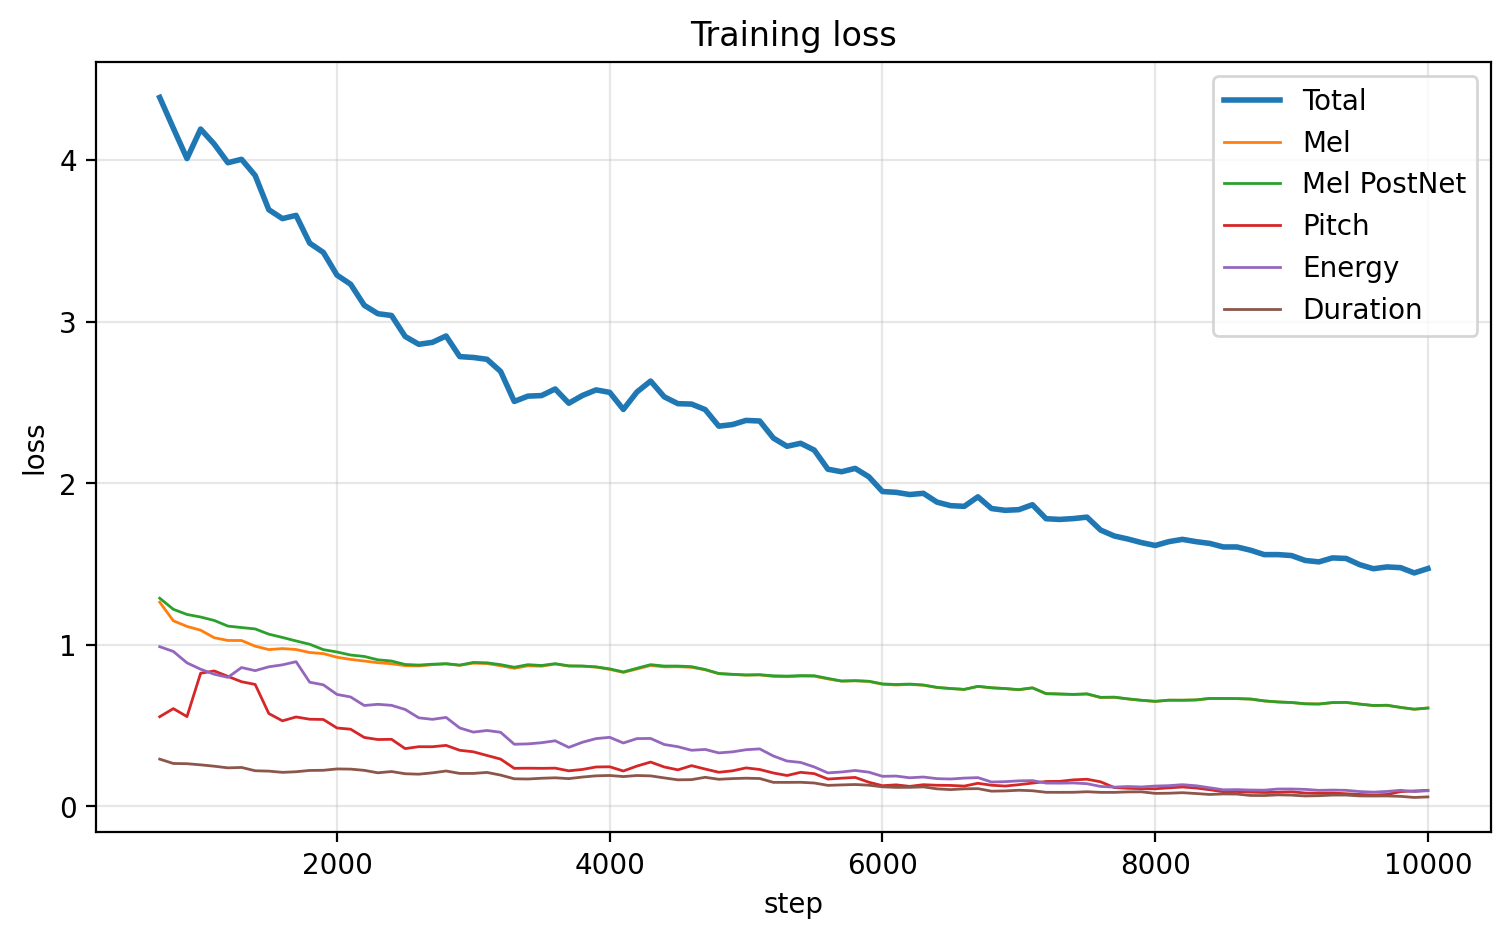

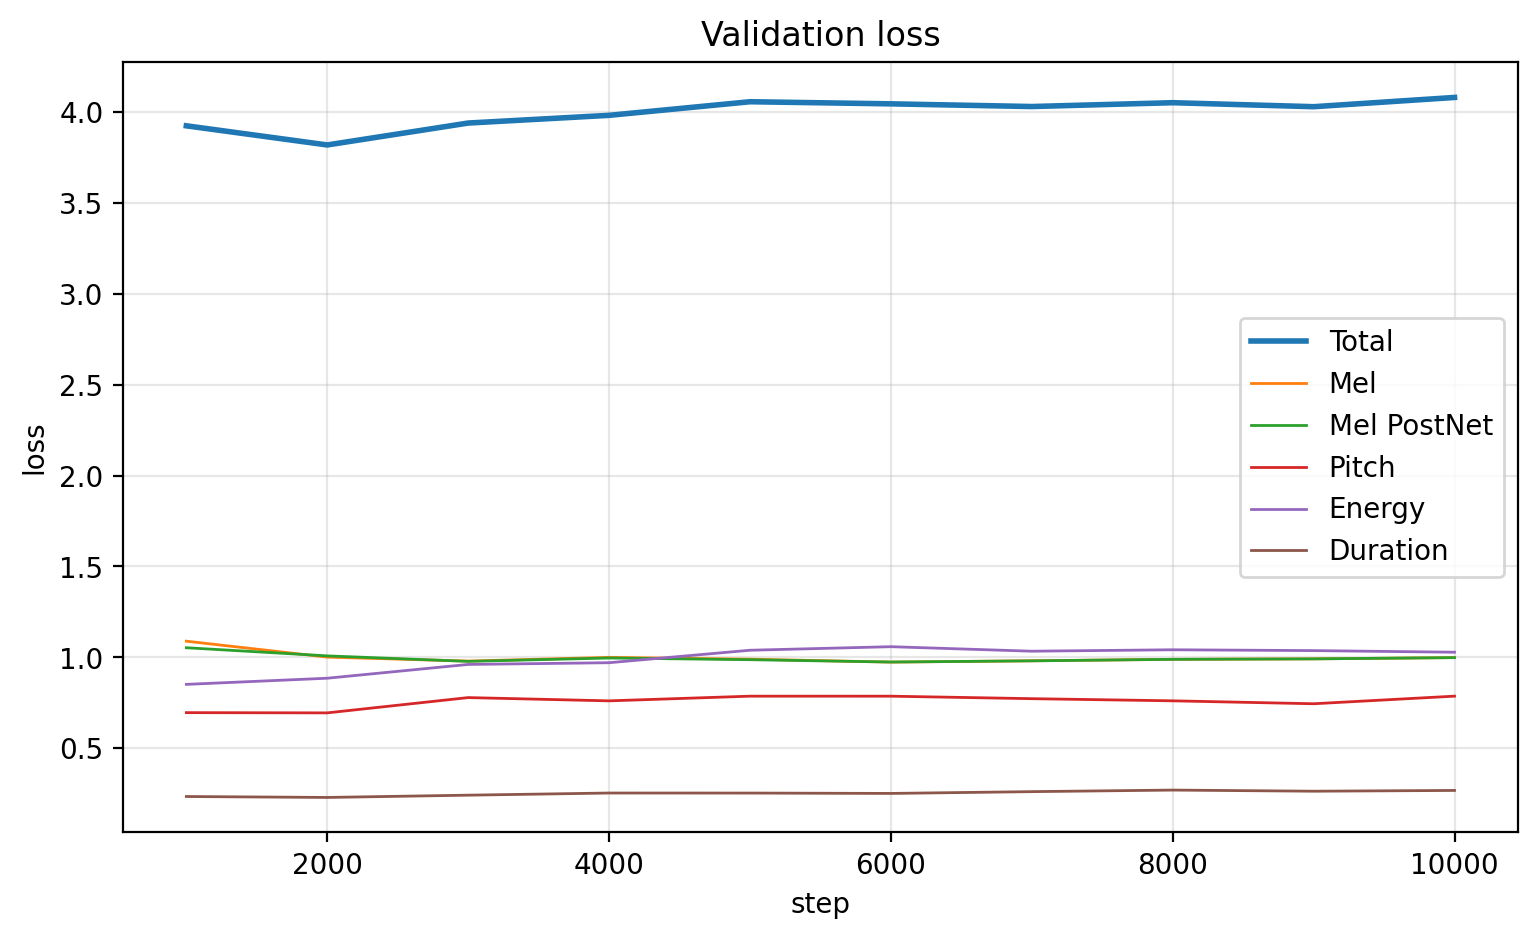

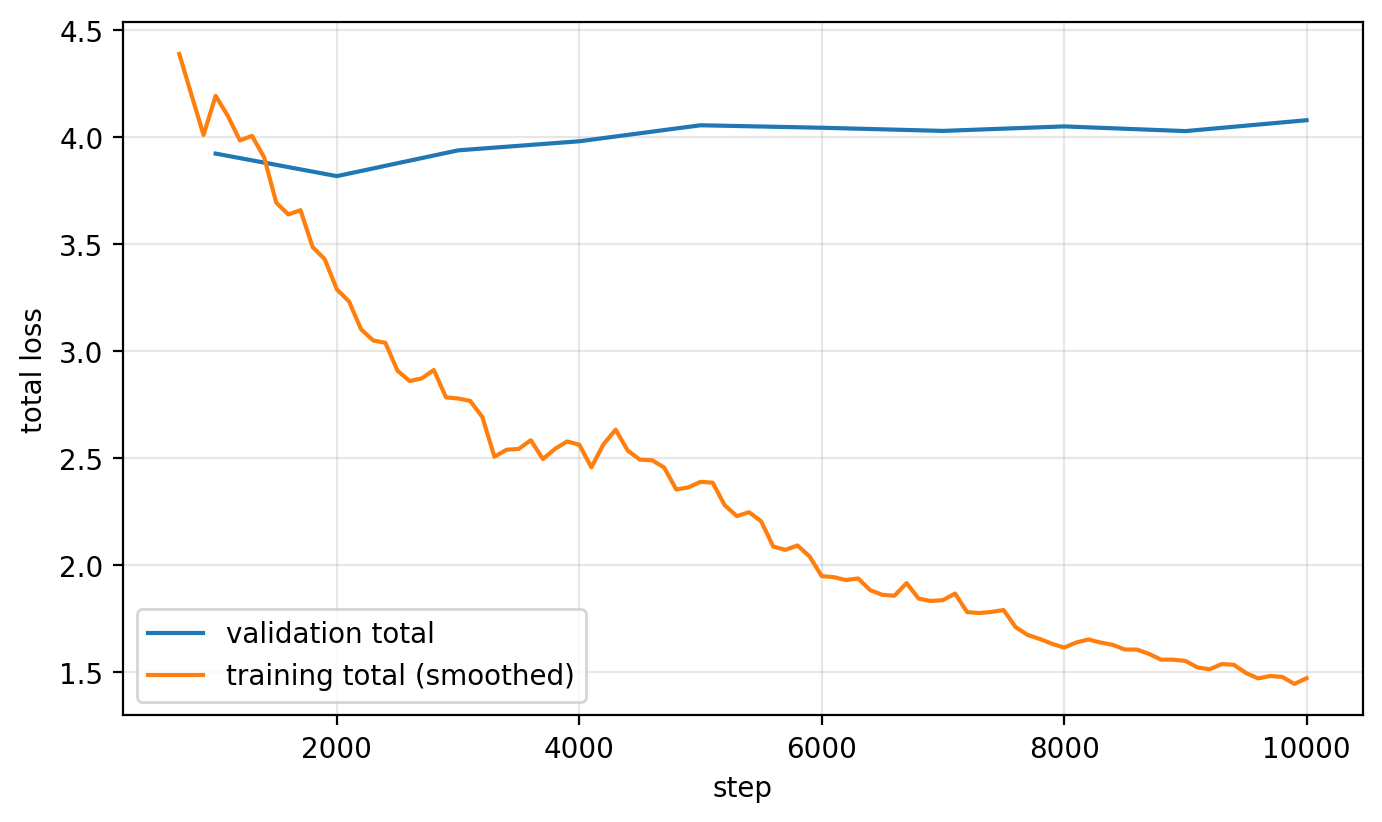

In [ ]:
%cd /content/project/English
!python plot_losses.py config.yaml ../Results/English

from IPython.display import Image, display
for f in ["training_loss", "validation_loss", "train_vs_val_total"]:
    display(Image(f"../Results/English/{f}.png"))

In [ ]:
%%bash
cd /content/project/English
grep -c pypinyin inference.py || true
for s in 2000 6000 10000; do
  python inference.py config.yaml --restore_step $s --speaker_id 2 --out /content/cmp/ck$s
done
ls /content/cmp/ck10000/test_generated_audios
ls /content/cmp/ck10000/variance_adaptor_plots/*

Traceback (most recent call last):
  File "/content/project/English/inference.py", line 10, in <module>
    from pypinyin import pinyin, Style
ModuleNotFoundError: No module named 'pypinyin'
Traceback (most recent call last):
  File "/content/project/English/inference.py", line 10, in <module>
    from pypinyin import pinyin, Style
ModuleNotFoundError: No module named 'pypinyin'
Traceback (most recent call last):
  File "/content/project/English/inference.py", line 10, in <module>
    from pypinyin import pinyin, Style
ModuleNotFoundError: No module named 'pypinyin'
ls: cannot access '/content/cmp/ck10000/test_generated_audios': No such file or directory
ls: cannot access '/content/cmp/ck10000/variance_adaptor_plots/*': No such file or directory


CalledProcessError: Command 'b'cd /content/project/English\nfor s in 2000 6000 10000; do\n  python inference.py config.yaml --restore_step $s --speaker_id 2 --out /content/cmp/ck$s\ndone\nls /content/cmp/ck10000/test_generated_audios\nls /content/cmp/ck10000/variance_adaptor_plots/*\n'' returned non-zero exit status 2.

In [ ]:
%%bash
cd /content/project/English
grep -c pypinyin inference.py || true
for s in 2000 6000 10000; do
  python inference.py config.yaml --restore_step $s --speaker_id 2 --out /content/cmp/ck$s
done
ls /content/cmp/ck10000/test_generated_audios
ls /content/cmp/ck10000/variance_adaptor_plots/*

1


Traceback (most recent call last):
  File "/content/project/English/inference.py", line 10, in <module>
    from pypinyin import pinyin, Style
ModuleNotFoundError: No module named 'pypinyin'
Traceback (most recent call last):
  File "/content/project/English/inference.py", line 10, in <module>
    from pypinyin import pinyin, Style
ModuleNotFoundError: No module named 'pypinyin'
Traceback (most recent call last):
  File "/content/project/English/inference.py", line 10, in <module>
    from pypinyin import pinyin, Style
ModuleNotFoundError: No module named 'pypinyin'
ls: cannot access '/content/cmp/ck10000/test_generated_audios': No such file or directory
ls: cannot access '/content/cmp/ck10000/variance_adaptor_plots/*': No such file or directory


CalledProcessError: Command 'b'cd /content/project/English\ngrep -c pypinyin inference.py || true\nfor s in 2000 6000 10000; do\n  python inference.py config.yaml --restore_step $s --speaker_id 2 --out /content/cmp/ck$s\ndone\nls /content/cmp/ck10000/test_generated_audios\nls /content/cmp/ck10000/variance_adaptor_plots/*\n'' returned non-zero exit status 2.

In [ ]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving inference.py to inference.py
['inference.py']


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
assert os.path.exists("/content/drive/MyDrive/fs2/preprocessed_Svarah.zip"), \
    "STOP: fs2 folder is not visible in this Google account. Share it and add the shortcut first."

if not os.path.exists("/content/inference.py"):
    from google.colab import files
    files.upload()      # click Choose files and select inference.py

%cd /content
!rm -rf project
!git clone https://github.com/Narmadas-31/fastspeech2-english-telugu.git project

!unzip -q -o /content/drive/MyDrive/fs2/preprocessed_Svarah.zip -d /content/
!mkdir -p /tmp/voc && unzip -q -o /content/drive/MyDrive/fs2/generator_universal.pth.tar.zip -d /tmp/voc
!find /tmp/voc -name generator_universal.pth.tar -exec cp {} /content/project/English/hifigan/ \;

%cd /content/project/English
!pip install -q inflect g2p_en unidecode pyworld tgt librosa scipy matplotlib tensorboard tqdm pyyaml
!python -c "from g2p_en import G2p; G2p()"
!python apply_patches.py

import re, shutil, torch
s = open("dataset.py", encoding="utf-8").read()
for k in ["pitch", "energy", "duration"]:
    s = s.replace(f"        {k} = np.load({k}_path).astype(np.float32)\n", "", 1)
s = s.replace("from utils.utils import to_device", "from utils.tools import to_device")
s = re.sub(
    r'preprocess_config = yaml\.load\(\s*open\("\./config/LJSpeech/preprocess\.yaml", "r"\), Loader=yaml\.FullLoader\s*\)\s*'
    r'train_config = yaml\.load\(\s*open\("\./config/LJSpeech/train\.yaml", "r"\), Loader=yaml\.FullLoader\s*\)',
    'cfg = yaml.load(open("config.yaml", "r"), Loader=yaml.FullLoader)\n'
    '    preprocess_config = cfg["preprocessing"]\n    train_config = cfg["train"]', s)
open("dataset.py", "w", encoding="utf-8").write(s)

m = open("utils/model.py", encoding="utf-8").read()
m = m.replace("torch.load(ckpt_path)", "torch.load(ckpt_path, map_location=device, weights_only=False)")
m = m.replace('torch.load("hifigan/generator_LJSpeech.pth.tar")', 'torch.load("hifigan/generator_LJSpeech.pth.tar", map_location=device, weights_only=False)')
m = m.replace('torch.load("hifigan/generator_universal.pth.tar")', 'torch.load("hifigan/generator_universal.pth.tar", map_location=device, weights_only=False)')
m = m.replace("model.requires_grad_ = False", "model.requires_grad_(False)")
open("utils/model.py", "w", encoding="utf-8").write(m)

t = open("utils/tools.py", encoding="utf-8").read()
t = t.replace("torch.from_numpy(energies).to(device)", "torch.from_numpy(energies).float().to(device)")
open("utils/tools.py", "w", encoding="utf-8").write(t)

shutil.copy("/content/inference.py", "/content/project/English/inference.py")
src = open("/content/project/English/inference.py").read()
print("has pypinyin    :", "pypinyin" in src, " <- must be False")
print("has restore_step:", "restore_step" in src, " <- must be True")
print("lines           :", len(src.splitlines()), " <- about 269")
print("checkpoints     :", sorted(os.listdir("/content/drive/MyDrive/fs2/output/English/ckpt")))

Mounted at /content/drive
/content
Cloning into 'project'...
remote: Enumerating objects: 104, done.
remote: Counting objects: 100% (104/104), done.
remote: Compressing objects: 100% (78/78), done.
remote: Total 104 (delta 25), reused 99 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (104/104), 1.39 MiB | 7.07 MiB/s, done.
Resolving deltas: 100% (25/25), done.
/content/project/English
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package cmudict to /root/nltk_data...
[nltk_data]   Unzipping corpora/cmudict.zip.
patched: preprocess.py
has pypinyin    : False  <- must be Fal

In [ ]:
import nltk
for pkg in ["averaged_perceptron_tagger_eng", "averaged_perceptron_tagger", "cmudict"]:
    nltk.download(pkg)

from g2p_en import G2p
print(G2p()("antidisestablishmentarianism"))

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package cmudict to /root/nltk_data...
[nltk_data]   Package cmudict is already up-to-date!


['AE2', 'N', 'T', 'AY0', 'D', 'IH0', 'S', 'AH0', 'S', 'T', 'AE2', 'B', 'L', 'IH0', 'SH', 'M', 'AH0', 'N', 'T', 'EH1', 'R', 'IY0', 'AH0', 'N', 'IH0', 'Z', 'AH0', 'M']


In [ ]:
%%bash
cd /content/project/English
for s in 2000 6000 10000; do
  python inference.py config.yaml --restore_step $s --speaker_id 2 --out /content/cmp/ck$s
done
ls /content/cmp/ck10000/test_generated_audios
ls /content/cmp/ck10000/variance_adaptor_plots/*

Removing weight norm...

[E1] The antidisestablishmentarianism movement gained considerable momentum during the parliamentary proceedings.
    phonemes: DH AH0 AE2 N T AY0 D IH0 S AH0 S T AE2 B L IH0 SH M AH0 N T EH1 R IY0 AH0 N IH0 Z AH0 M M UW1 V M AH0 N T G EY1 N D K AH0 N S IH1 D ER0 AH0 B AH0 L M OW0 M EH1 N T AH0 M D UH1 R IH0 NG DH AH0 P AA2 R L AH0 M EH1 N ER0 IY0 P R AH0 S IY1 D IH0 NG Z
    audio: 6.08 s, 86 phonemes

[E2a] The orchestra's conduct during the ceremony was praised by the audience.
    phonemes: DH AH0 AO1 R K AH0 S T R AH0 Z K AA1 N D AH0 K T D UH1 R IH0 NG DH AH0 S EH1 R AH0 M OW2 N IY0 W AO1 Z P R EY1 Z D B AY1 DH AH0 AA1 D IY0 AH0 N S
    audio: 3.96 s, 51 phonemes

[E2b] The researchers will conduct an experiment to evaluate the proposed method.
    phonemes: DH AH0 R IY1 S ER0 CH ER0 Z W AH0 L K AA1 N D AH0 K T AE1 N IH0 K S P EH1 R M AH0 N T T UW1 IY0 V AE1 L Y UW0 EY2 T DH AH0 P R AH0 P OW1 Z D M EH1 TH AH0
    audio: 4.26 s, 54 phonemes

[E3] The rhyth 

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


heteronym experiment

In [ ]:
%%bash
cd /content/project/English
python inference.py config.yaml --restore_step 10000 --speaker_id 2 --fix_heteronyms --out /content/cmp/ck10000_heteronym 2>&1 | grep -A2 -E "^\[E2"

[E2a] The orchestra's conduct during the ceremony was praised by the audience.
    phonemes: DH AH0 AO1 R K AH0 S T R AH0 Z K AA1 N D AH0 K T D UH1 R IH0 NG DH AH0 S EH1 R AH0 M OW2 N IY0 W AO1 Z P R EY1 Z D B AY1 DH AH0 AA1 D IY0 AH0 N S
    audio: 4.49 s, 51 phonemes
--
[E2b] The researchers will conduct an experiment to evaluate the proposed method.
    phonemes: DH AH0 R IY1 S ER0 CH ER0 Z W AH0 L K AH0 N D AH1 K T AE1 N IH0 K S P EH1 R M AH0 N T T UW1 IY0 V AE1 L Y UW0 EY2 T DH AH0 P R AH0 P OW1 Z D M EH1 TH AH0
    audio: 4.05 s, 54 phonemes


In [ ]:
from IPython.display import Audio, display
for s in [2000, 6000, 10000]:
    for sid in ["E1", "E3", "E4"]:
        print(f"checkpoint {s} - {sid}")
        display(Audio(f"/content/cmp/ck{s}/test_generated_audios/{sid}.wav"))
for tag, d in [("default", "ck10000"), ("heteronym fix", "ck10000_heteronym")]:
    for sid in ["E2a", "E2b"]:
        print(tag, "-", sid)
        display(Audio(f"/content/cmp/{d}/test_generated_audios/{sid}.wav"))

checkpoint 2000 - E1


checkpoint 2000 - E3


checkpoint 2000 - E4


checkpoint 6000 - E1


checkpoint 6000 - E3


checkpoint 6000 - E4


... (3 outputs left out)

default - E2a


default - E2b


heteronym fix - E2a


heteronym fix - E2b


duration


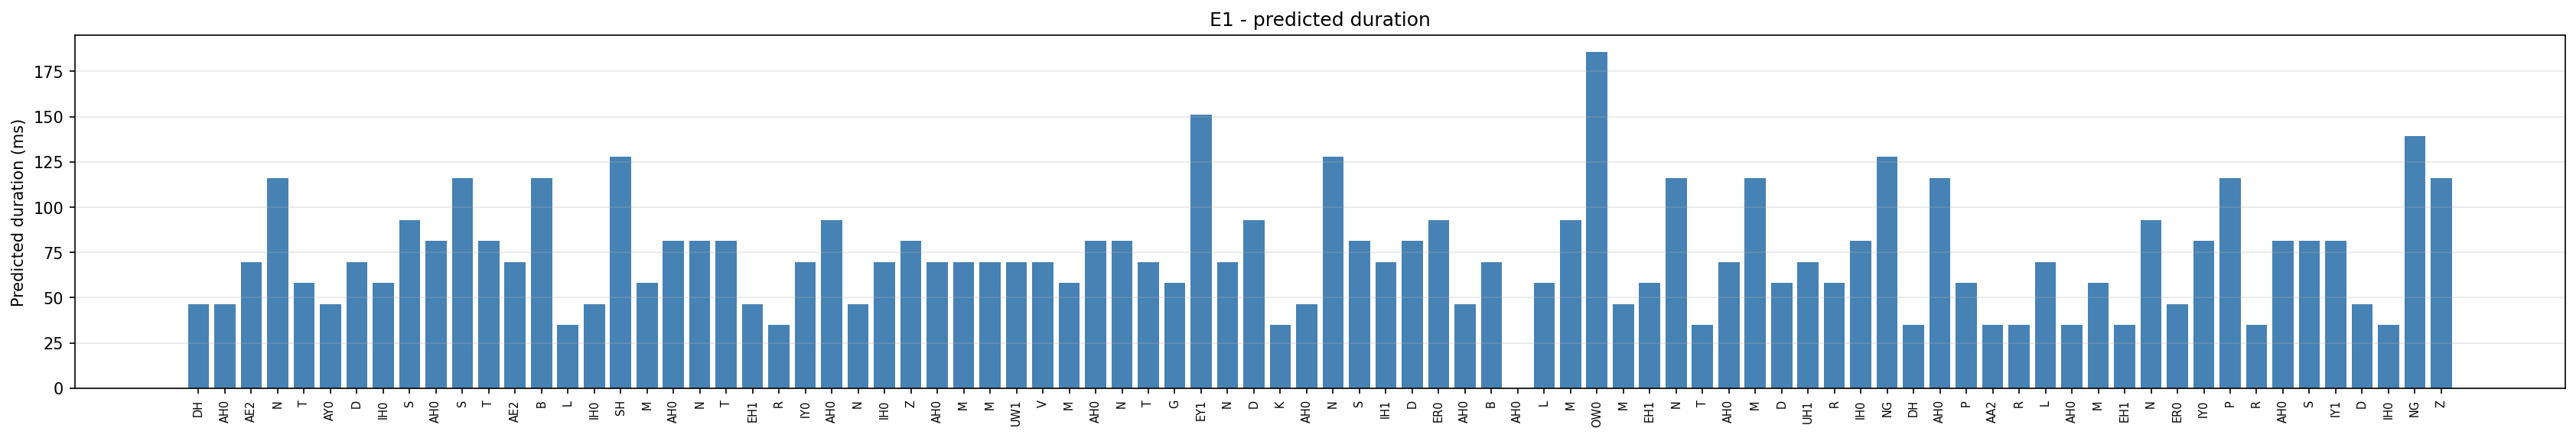

pitch


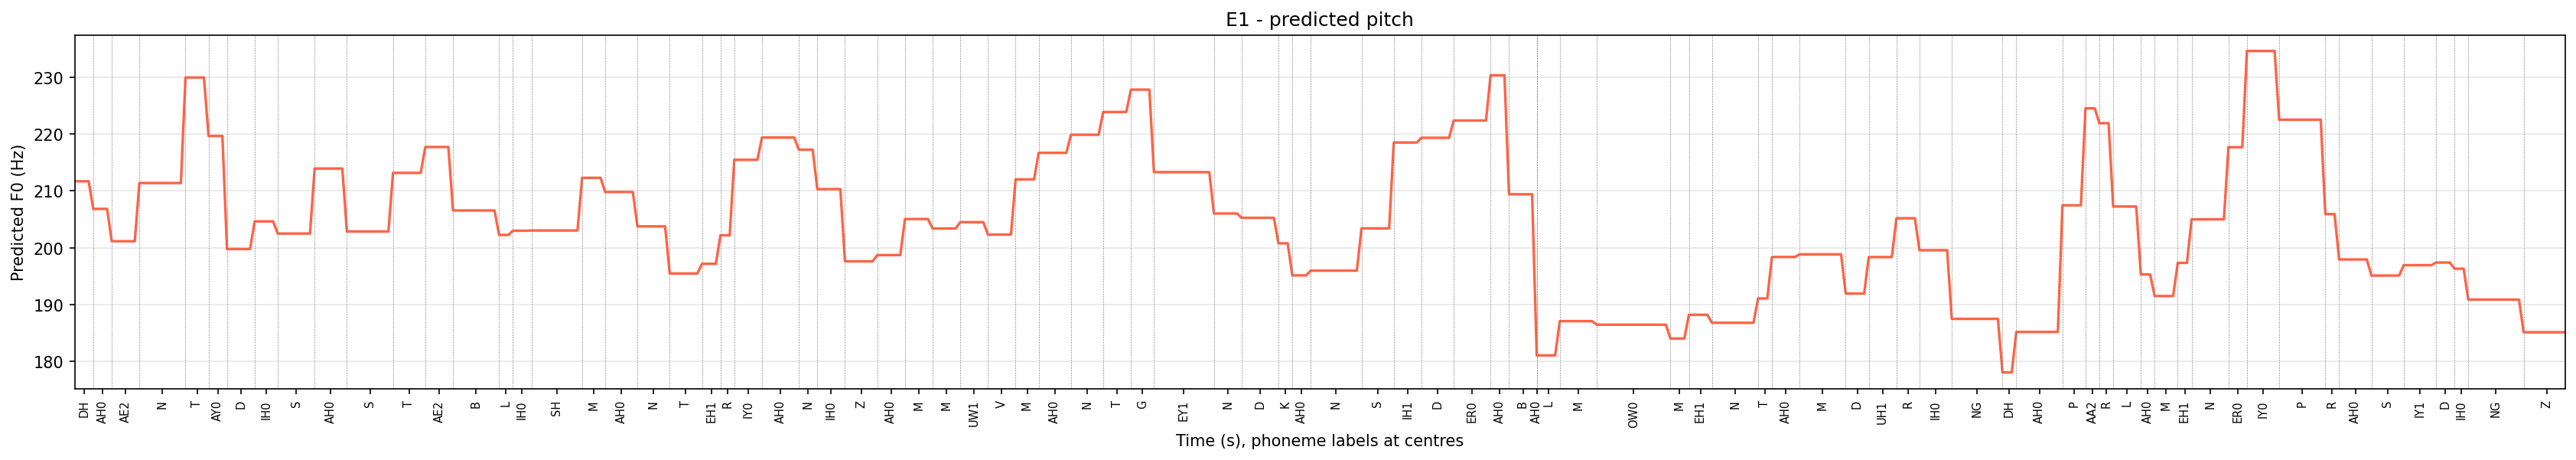

energy


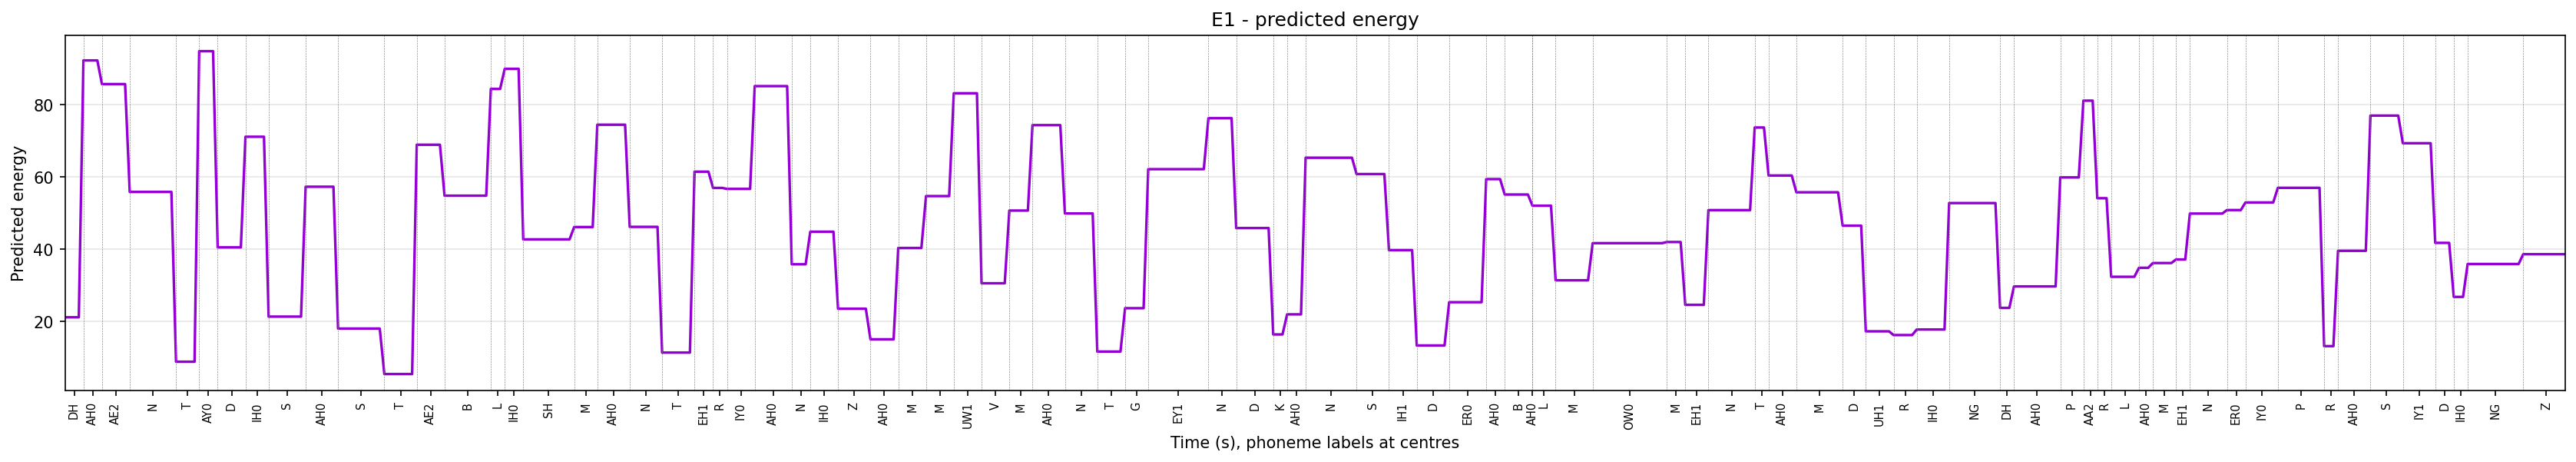

In [ ]:
from IPython.display import Image, display
for k in ["duration", "pitch", "energy"]:
    print(k)
    display(Image(f"/content/cmp/ck10000/variance_adaptor_plots/{k}/E1.png"))

In [ ]:
BEST = 10000
import os, shutil
%cd /content/project/English
os.makedirs("/content/project/Results", exist_ok=True)
shutil.rmtree("/content/project/Results/English", ignore_errors=True)
shutil.copytree(f"/content/cmp/ck{BEST}", "/content/project/Results/English")
shutil.rmtree("/content/project/Results/English_extra", ignore_errors=True)
shutil.copytree("/content/cmp/ck10000_heteronym", "/content/project/Results/English_extra/heteronym_fix")
!python plot_losses.py config.yaml ../Results/English
!ls /content/project/Results/English

/content/project/English
train points: 98 val points: 10
test_generated_audios  train_vs_val_total.png  variance_adaptor_plots
training_loss.png      validation_loss.png


In [ ]:
!mkdir -p /content/drive/MyDrive/fs2/backup/fixed_code/utils
!cp -r /content/project/Results /content/drive/MyDrive/fs2/backup/
!cp -r /content/cmp /content/drive/MyDrive/fs2/backup/
%cd /content/project/English
!cp dataset.py config.yaml inference.py plot_losses.py /content/drive/MyDrive/fs2/backup/fixed_code/
!cp utils/model.py utils/tools.py /content/drive/MyDrive/fs2/backup/fixed_code/utils/

!cd /content/project && zip -rq /content/Results_English.zip Results
!cd /content/project/English && zip -q /content/fixed_code.zip dataset.py inference.py utils/model.py utils/tools.py
from google.colab import files
files.download("/content/Results_English.zip")
files.download("/content/fixed_code.zip")

/content/project/English


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/content/project/English
train points: 98 val points: 10


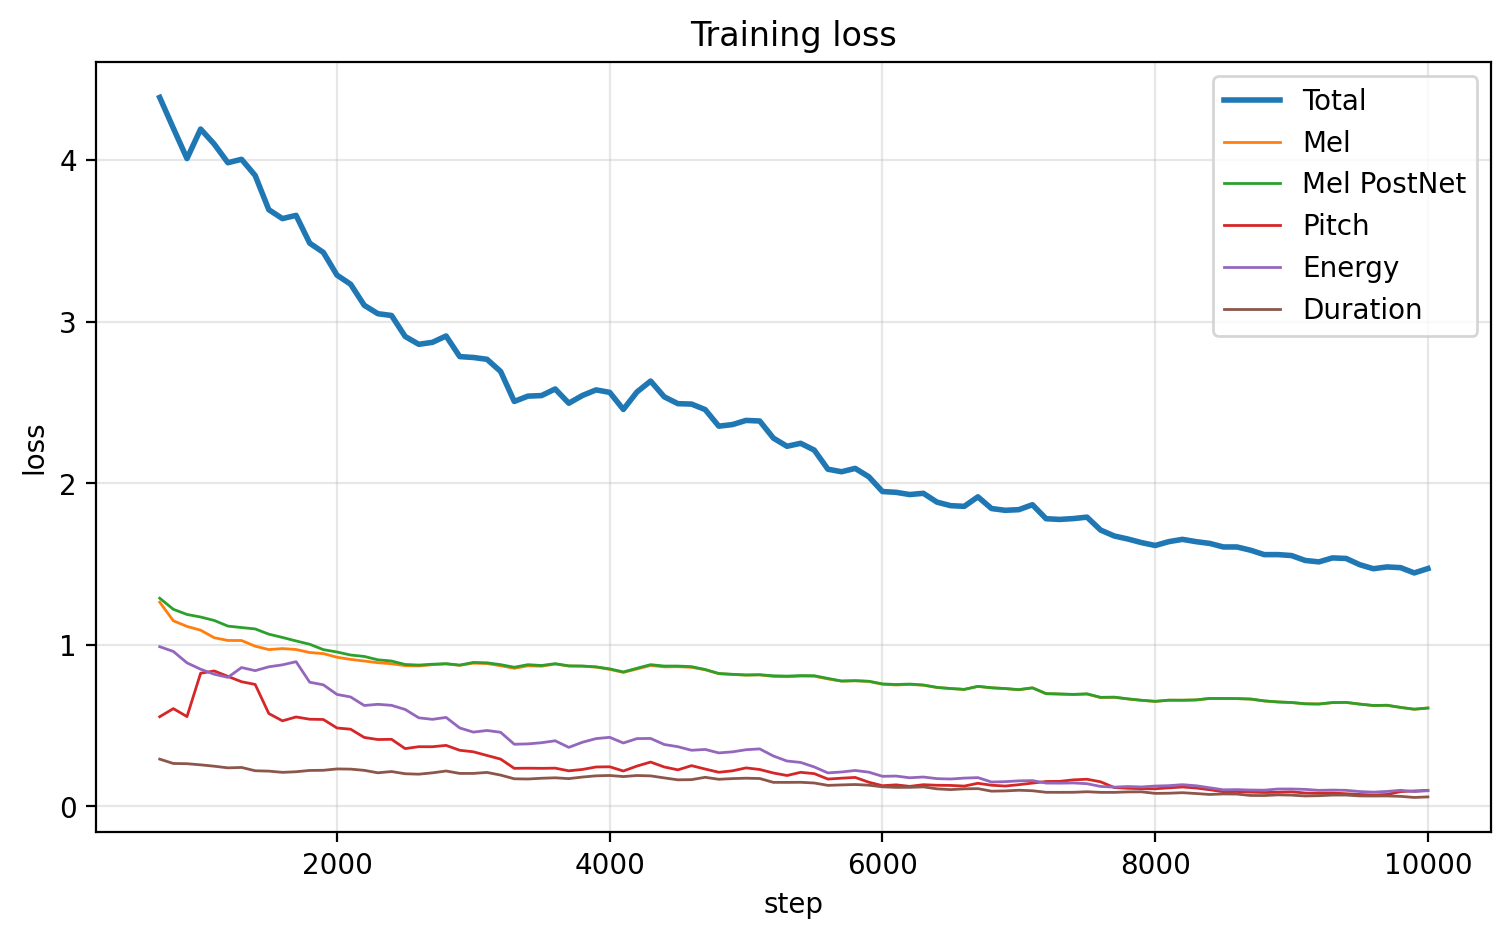

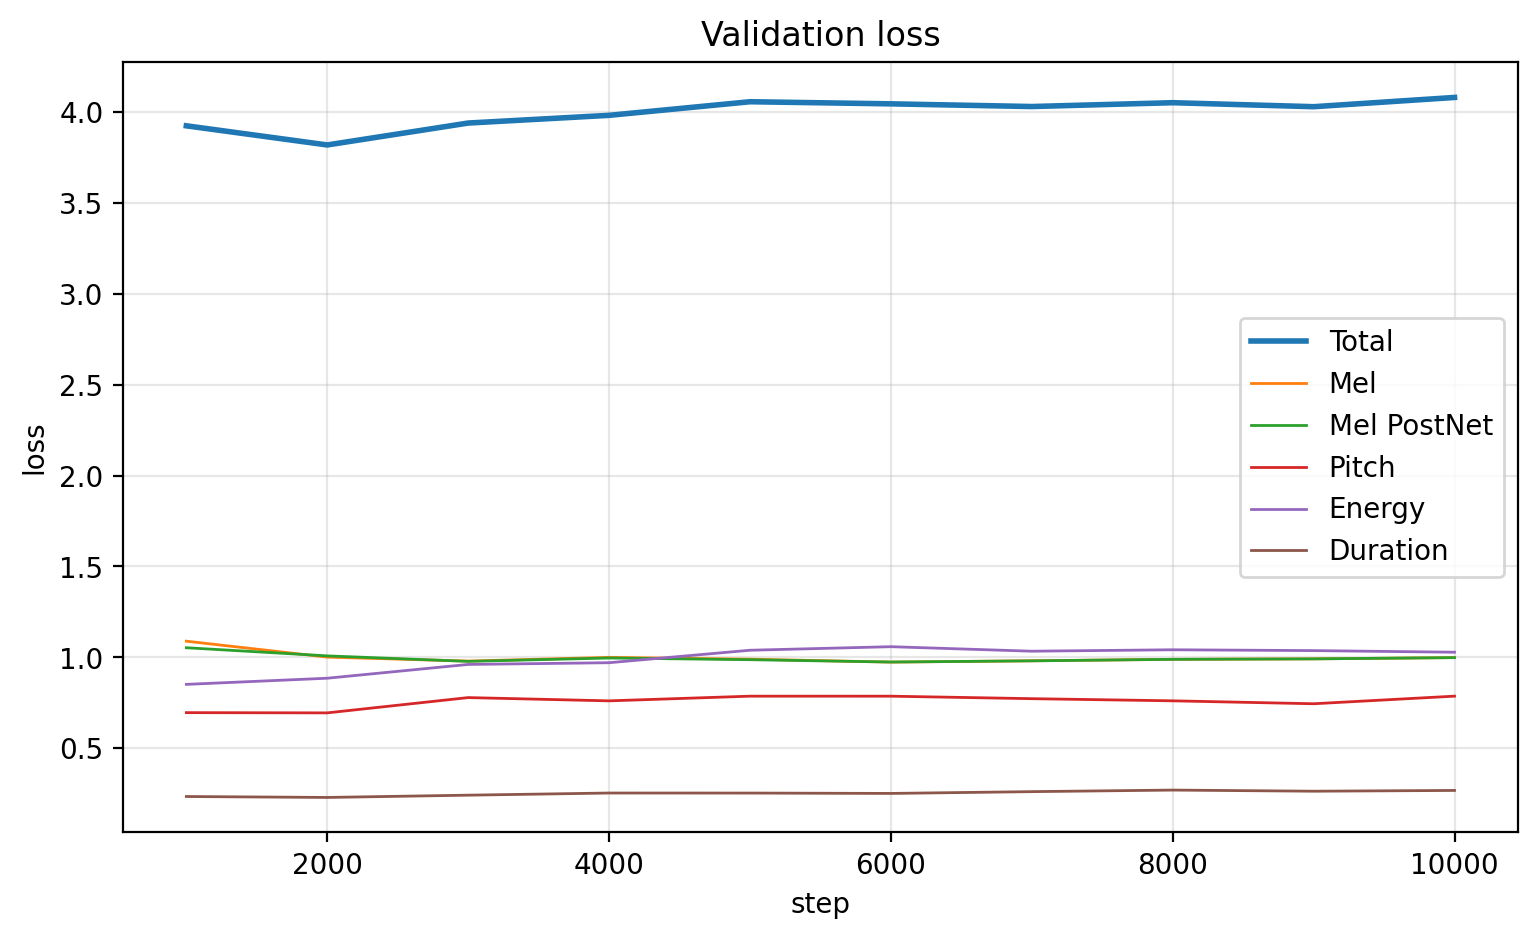

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
%cd /content/project/English
!python plot_losses.py config.yaml ../Results/English

from IPython.display import Image, display
for f in ["training_loss", "validation_loss"]:
    display(Image(f"/content/project/Results/English/{f}.png"))

!cd /content/project && zip -rq /content/Results_English.zip Results
from google.colab import files
files.download("/content/Results_English.zip")